# Power Markets — Trading and Hedging a Retail Electricity Portfolio
### HTW Summer School Project · Ostrom GmbH

One notebook, two halves.

**Part 1 — Data Briefing.** Understand the customer book and the market data
before deciding anything. Four exhibits, plus the data checks that let us trust
the rest.

**Part 2 — Main Project.** Design the 2024 hedge, run it through delivery, and
recommend a strategy. Seven stages.

Part 2 builds directly on Part 1: the scaled customer portfolio, the
`market_activity >= 100` liquidity rule, and the non-overlapping product sets all
come from the exhibits below and are reused rather than recomputed.

| | Section | Question it answers |
|---|---|---|
| **Part 1** | Step 0 | Can we trust the data? |
| | Exhibit 1 | How much do we sell, and when? |
| | Exhibit 2 | What can we buy, and what is actually tradable? |
| | Exhibit 3 | Which hours are normally expensive? |
| | Exhibit 4 | What did 2024 actually do? |
| **Part 2** | Stage 1 | Forecast the customer load |
| | Stage 2 | Build an hourly price curve (HPFC) |
| | Stage 3 | Choose the futures positions |
| | Stage 4 | Buy the rest Day-Ahead |
| | Stage 5 | Settle what we got wrong |
| | Stage 6 | Compare and recommend |
| | Stage 7 | The worst price day of 2024 |

**A note on time.** Everything sits on a **quarter-hourly** grid — 15-minute
blocks. 2024 is a leap year: 8,784 hours, **35,136** quarter-hours. That number
recurs constantly.

*Disclaimer: simplified educational exercise; not trading or risk-management advice.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from scipy.optimize import minimize

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.width', 200)

# ---- validated palette (see project dataviz skill) -------------------------
INK        = '#0b0b0b'
INK_SEC    = '#52514e'
INK_MUTE   = '#898781'
GRID       = '#e1e0d9'
BASELINE   = '#c3c2b7'
SURFACE    = '#fcfcfb'

BLUE   = '#2a78d6'   # categorical slot 1
ORANGE = '#eb6834'   # categorical slot 2
AQUA   = '#1baf7a'   # categorical slot 3
RED    = '#e34948'   # categorical slot 8 (diverging warm pole)
GRAY   = '#f0efec'   # diverging neutral midpoint

plt.rcParams.update({
    'figure.facecolor': SURFACE,   'axes.facecolor':   SURFACE,
    'axes.edgecolor':   BASELINE,  'axes.labelcolor':  INK_SEC,
    'axes.grid':        True,      'grid.color':       GRID,
    'grid.linewidth':   0.8,       'text.color':       INK,
    'xtick.color':      INK_MUTE,  'ytick.color':      INK_MUTE,
    'font.family':      'sans-serif', 'font.size':     10.5,
    'axes.titlesize':   12,        'axes.titleweight': 'bold',
    'axes.titlecolor':  INK,       'axes.spines.top':  False,
    'axes.spines.right': False,    'legend.frameon':   False,
    # date axes must be drawn in Berlin time, not matplotlib's UTC default
    'timezone': 'Europe/Berlin',
})

FIGURES = {}          # every chart is kept here so the appendix can reuse it

DATA, DT_H, TZ = 'Data', 0.25, 'Europe/Berlin'   # DT_H = one quarter-hour in hours

# Part 2 compares three strategies - fixed colour each, never reassigned
STRATEGIES = ['UNHEDGED', 'COARSE_CAL', 'GRANULAR']
SCOL = {'UNHEDGED': BLUE, 'COARSE_CAL': ORANGE, 'GRANULAR': AQUA}

def to_local(col):
    '''The timestamp_local column carries its own UTC offset (+01:00 in winter,
    +02:00 in summer). Parsing it as UTC first and converting afterwards is the
    only way to get a consistent Berlin wall-clock across both DST changes.'''
    return pd.to_datetime(col, format='ISO8601', utc=True).dt.tz_convert('Europe/Berlin')

---
---
# PART 1 — Data Briefing

We supply electricity to 10,220 customers in Berlin. Next year (2024) we have to
buy that electricity on the wholesale market. Before deciding **how**, we need to
understand what our customers use and what the market is offering.

No hedge is designed in Part 1. This is the homework you do first.

---
## Step 0 — Check the data before trusting it

Six files were handed to us. Before drawing a single chart it is worth asking
three boring questions, because if the answer to any of them is wrong,
everything downstream is quietly wrong too.

1. **Does every file have the same number of rows?** They all have to sit on the
   same 15-minute grid, otherwise we cannot line them up.
2. **Are the Day-Ahead prices really hourly?** The brief says each hourly price
   is simply repeated four times. If that is true, Day-Ahead has no 15-minute
   detail in it and we should not pretend otherwise.
3. **Do the clock changes appear?** Germany moves the clock twice a year. In
   March one hour disappears; in October one hour happens twice. If the data did
   not show this, the timestamps would be fake.

In [2]:
files = {
    'slp_profiles.csv':          'Customer load shapes (Berlin HB, GB, LB)',
    'futures_prices.csv':        'Futures quoted on 29 Sep 2023 for 2024',
    'shape_factors.csv':         'Historical price shape from 2019-2022',
    'day_ahead_prices.csv':      'Realised 2024 Day-Ahead prices',
    'imbalance_prices.csv':      'Realised 2024 imbalance prices (reBAP)',
    'actual_portfolio_load.csv': 'What customers really used in 2024',
}
inventory = pd.DataFrame([
    {'file': f, 'rows': len(pd.read_csv(f'{DATA}/{f}')), 'contains': d}
    for f, d in files.items()
])
inventory

,file,rows,contains
0,slp_profiles.csv,35136,"Customer load shapes (Berlin HB, GB, LB)"
1,futures_prices.csv,34,Futures quoted on 29 Sep 2023 for 2024
2,shape_factors.csv,35136,Historical price shape from 2019-2022
3,day_ahead_prices.csv,35136,Realised 2024 Day-Ahead prices
4,imbalance_prices.csv,35136,Realised 2024 imbalance prices (reBAP)
5,actual_portfolio_load.csv,35136,What customers really used in 2024


In [3]:
da  = pd.read_csv(f'{DATA}/day_ahead_prices.csv')
imb = pd.read_csv(f'{DATA}/imbalance_prices.csv')

# group the quarter-hours into clock hours - do this in UTC, because in local
# time the October hour occurs twice and cannot be grouped unambiguously
hour_utc = pd.to_datetime(da['timestamp_utc'], format='ISO8601', utc=True).dt.floor('h')

da_varies  = (da.groupby(hour_utc)['day_ahead_price_eur_mwh'].nunique() > 1).sum()
imb_flat   = (imb.groupby(hour_utc)['imbalance_price_eur_mwh'].nunique() == 1).sum()
n_hours    = hour_utc.nunique()

print(f"Clock hours in 2024                                    : {n_hours:,}")
print(f"Hours where the 4 Day-Ahead quarter-values DIFFER      : {da_varies:,}  -> Day-Ahead is hourly")
print(f"Hours where the 4 reBAP quarter-values are ALL EQUAL   : {imb_flat:,}  -> reBAP is truly quarter-hourly")

# the two clock changes, counted on the local grid
loc   = to_local(da['timestamp_local'])
daily = loc.dt.date.value_counts()
print(f"\nDays with only 92 quarter-hours (spring, hour lost)    : "
      f"{sorted(str(d) for d, n in daily.items() if n == 92)}")
print(f"Days with 100 quarter-hours (autumn, hour repeated)    : "
      f"{sorted(str(d) for d, n in daily.items() if n == 100)}")

Clock hours in 2024                                    : 8,784
Hours where the 4 Day-Ahead quarter-values DIFFER      : 0  -> Day-Ahead is hourly
Hours where the 4 reBAP quarter-values are ALL EQUAL   : 1  -> reBAP is truly quarter-hourly

Days with only 92 quarter-hours (spring, hour lost)    : ['2024-03-31']
Days with 100 quarter-hours (autumn, hour repeated)    : ['2024-10-27']


**What we found.**

- All six files have exactly **35,136 rows**, so they line up one-to-one.
- Day-Ahead is **hourly**: in all 8,784 hours the four quarter-values are
  identical. So a Day-Ahead price is a flat step across the hour, and any
  15-minute pattern we later see in our *costs* comes from our *load*, not from
  the price.
- reBAP is the opposite — only 1 hour out of 8,784 happens to have four equal
  values. It genuinely moves every 15 minutes.
- **The clock changes are in the data.** 31 March has 92 quarter-hours instead
  of 96 (the 02:00 hour never happens) and 27 October has 100 (the 02:00 hour
  happens twice). This is the "anything unusual" the brief asks us to note. It
  matters more than it sounds: any calculation that assumes "March = 31 × 96
  intervals" will be wrong, and later on we count intervals to split Base and
  Peak prices. We count them from the real grid instead of the calendar.

---
# Exhibit 1 — Customer portfolio

**Inputs:** the customer table below and `slp_profiles.csv`.

| Profile | Customer type | Customers | Yearly use each |
|---|---|---|---|
| HB | Household | 10,000 | 3.5 MWh |
| GB | General commercial | 200 | 30.0 MWh |
| LB | Agriculture | 20 | 100.0 MWh |

### The problem, and how we solve it

Our small customers have no smart meters, so nobody knows what any single one of
them used at 14:15 on a Tuesday. What we do have is a **standard load profile**
(SLP) published by Stromnetz Berlin for each customer type — an official curve
saying how a typical household spreads its yearly electricity across the year.

The SLP gives us the **shape**. The customer table gives us the **size**. We just
have to put them together.

**Step 1 — how much energy?** Customers × yearly use each:

```
E_p  =  n_p  x  e_p

energy the group needs  =  how many customers  x  how much each uses per year
```

**Step 2 — what shape?** Add up the whole SLP column and see what it comes to.
Then scale it so the total matches $E_p$:

```
                    s_p,t
L_p,t  =  E_p  x  ---------
                   sum(s_p)

load in this quarter-hour  =  group's yearly energy  x  this interval's share of the year
```

The fraction $s_{p,t} / \sum_\tau s_{p,\tau}$ is just "what share of the year's
energy falls in this quarter-hour". Multiply the shares by the yearly total and
you have the forecast.

In [4]:
slp = pd.read_csv(f'{DATA}/slp_profiles.csv')
slp['timestamp_local'] = to_local(slp['timestamp_local'])

customers = {
    'hb': {'name': 'Household (HB)',          'n': 10_000, 'e': 3.5,   'col': 'hb_normalized_kwh'},
    'gb': {'name': 'General commercial (GB)', 'n': 200,    'e': 30.0,  'col': 'gb_normalized_kwh'},
    'lb': {'name': 'Agriculture (LB)',        'n': 20,     'e': 100.0, 'col': 'lb_normalized_kwh'},
}
COLORS = {'hb': BLUE, 'gb': ORANGE, 'lb': AQUA}

# first: what ARE the units? look at the raw column before scaling anything
units = pd.DataFrame([
    {'profile': m['name'],
     'raw annual sum (kWh)': slp[m['col']].sum(),
     'raw annual sum (MWh)': slp[m['col']].sum() / 1000}
    for m in customers.values()
])
units

,profile,raw annual sum (kWh),raw annual sum (MWh)
0,Household (HB),"1,000,000.00","1,000.00"
1,General commercial (GB),"1,000,000.00","1,000.00"
2,Agriculture (LB),"1,000,000.00","1,000.00"


**A useful surprise.** Each profile adds up to exactly **1,000,000 kWh = 1,000 MWh**
per year. The profiles are pre-normalized to a round number, which makes the
scaling factor trivial to read: it is simply the group's annual energy divided
by 1,000.

- Household: 35,000 MWh ÷ 1,000 = **×35**
- Commercial: 6,000 MWh ÷ 1,000 = **×6**
- Agriculture: 2,000 MWh ÷ 1,000 = **×2**

This also confirms the units are **kWh**, not MWh — a factor of 1,000 that would
have made our whole portfolio 43 GWh instead of 43 MWh if we had missed it.

In [5]:
portfolio = pd.DataFrame({'timestamp_local': slp['timestamp_local']})
rows = []
for p, meta in customers.items():
    E_p   = meta['n'] * meta['e']                     # MWh needed for the year
    s     = slp[meta['col']]                          # the shape, in kWh
    scale = E_p / (s.sum() / 1000)                    # one number for all 35,136 intervals
    portfolio[f'{p}_mwh'] = s / 1000 * scale          # MWh per quarter-hour
    rows.append({'profile': meta['name'], 'customers': meta['n'],
                 'MWh each': meta['e'], 'scaling factor': scale,
                 'annual MWh target': E_p,
                 'annual MWh after scaling': portfolio[f'{p}_mwh'].sum()})

portfolio['total_mwh'] = portfolio[[f'{p}_mwh' for p in customers]].sum(axis=1)

summary = pd.DataFrame(rows)
summary['difference'] = summary['annual MWh after scaling'] - summary['annual MWh target']
summary['share %']    = summary['annual MWh after scaling'] / summary['annual MWh after scaling'].sum() * 100
summary

,profile,customers,MWh each,scaling factor,annual MWh target,annual MWh after scaling,difference,share %
0,Household (HB),10000,3.50,35.00,"35,000.00","35,000.00",0.00,81.40
1,General commercial (GB),200,30.00,6.00,"6,000.00","6,000.00",-0.00,13.95
2,Agriculture (LB),20,100.00,2.00,"2,000.00","2,000.00",0.00,4.65


In [6]:
E_total = portfolio['total_mwh'].sum()
hours   = len(portfolio) * DT_H

print(f"Total annual energy        : {E_total:,.1f} MWh")
print(f"Average load               : {E_total / hours:,.2f} MW")
print(f"Highest quarter-hour       : {portfolio['total_mwh'].max() / DT_H:,.2f} MW")
print(f"Lowest quarter-hour        : {portfolio['total_mwh'].min() / DT_H:,.2f} MW")
print(f"Highest / lowest           : {portfolio['total_mwh'].max() / portfolio['total_mwh'].min():,.1f}x")

Total annual energy        : 43,000.0 MWh
Average load               : 4.90 MW
Highest quarter-hour       : 10.40 MW
Lowest quarter-hour        : 1.68 MW
Highest / lowest           : 6.2x


**The reconciliation.** The `difference` column is zero for all three groups.
Our scaled profiles deliver exactly the energy the customer table promised.

This check is not a formality. If the clock changes had been mishandled — if
those four missing March intervals had been silently filled in, or the four
repeated October ones dropped — this column would not be zero. It is our proof
that the time handling is sound.

**MWh and MW are not the same thing, and mixing them costs a factor of 4.**
A quarter-hour is a quarter of an hour, so:

```
         MWh
MW  =  -------          (a quarter-hour is 0.25 of an hour)
        0.25
```

We sell **43,000 MWh** across the year. Spread evenly that would be **4.90 MW**
running constantly. But the real load swings between **1.68 MW** and **10.40 MW**
— the busiest moment is more than six times the quietest. Futures are sold in
MW; our customers are measured in MWh. Every number in this project keeps the
two apart on purpose.

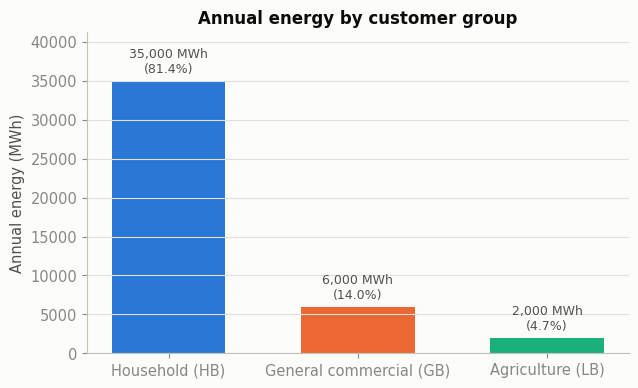

Total portfolio: 43,000 MWh per year


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(summary['profile'], summary['annual MWh after scaling'],
              color=[COLORS[p] for p in customers], width=0.6)
for b, pct in zip(bars, summary['share %']):
    ax.annotate(f"{b.get_height():,.0f} MWh\n({pct:.1f}%)",
                (b.get_x() + b.get_width() / 2, b.get_height()),
                ha='center', va='bottom', fontsize=9, color=INK_SEC,
                xytext=(0, 4), textcoords='offset points')
ax.set_ylabel('Annual energy (MWh)')
ax.set_title('Annual energy by customer group')
ax.grid(axis='x'); ax.margins(y=0.18)
FIGURES['ex1_portfolio_composition'] = fig
plt.tight_layout(); plt.show()

print(f"Total portfolio: {E_total:,.0f} MWh per year")

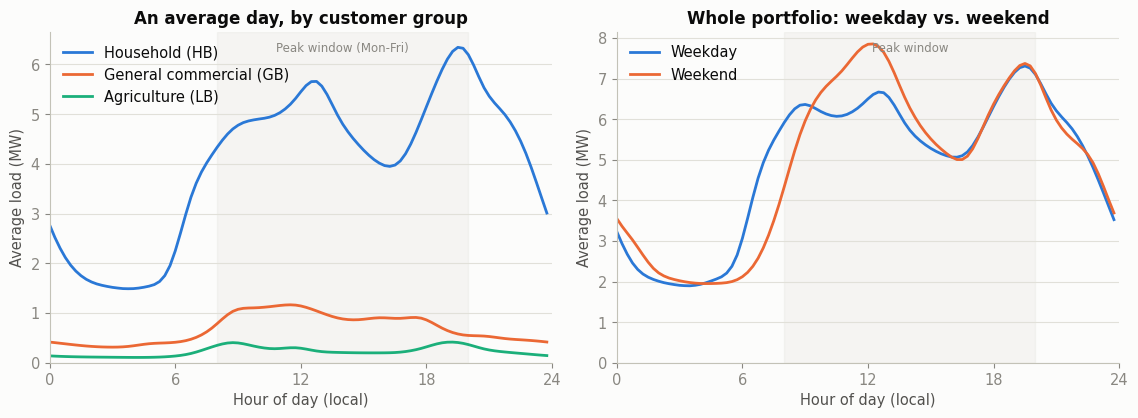

Energy used inside the Peak window : 44.5%
Share of the year that IS Peak     : 35.8%
Energy used at weekends            : 28.5%


In [8]:
portfolio['hour']       = portfolio['timestamp_local'].dt.hour + portfolio['timestamp_local'].dt.minute / 60
portfolio['is_weekend'] = portfolio['timestamp_local'].dt.weekday >= 5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

for p, meta in customers.items():
    ax1.plot(portfolio.groupby('hour')[f'{p}_mwh'].mean() / DT_H,
             color=COLORS[p], linewidth=2, label=meta['name'])
ax1.axvspan(8, 20, color=BASELINE, alpha=0.12, zorder=0)
ax1.text(14, 0.97, 'Peak window (Mon-Fri)', transform=ax1.get_xaxis_transform(),
         ha='center', va='top', color=INK_MUTE, fontsize=8.5)
ax1.set_xlabel('Hour of day (local)'); ax1.set_ylabel('Average load (MW)')
ax1.set_title('An average day, by customer group')
ax1.set_xlim(0, 24); ax1.set_xticks(range(0, 25, 6)); ax1.set_ylim(bottom=0)
ax1.margins(y=0.2); ax1.legend(loc='upper left'); ax1.grid(axis='x')

wd = portfolio[~portfolio.is_weekend].groupby('hour')['total_mwh'].mean() / DT_H
we = portfolio[portfolio.is_weekend].groupby('hour')['total_mwh'].mean() / DT_H
ax2.plot(wd, color=BLUE,   linewidth=2, label='Weekday')
ax2.plot(we, color=ORANGE, linewidth=2, label='Weekend')
ax2.axvspan(8, 20, color=BASELINE, alpha=0.12, zorder=0)
ax2.text(14, 0.97, 'Peak window', transform=ax2.get_xaxis_transform(),
         ha='center', va='top', color=INK_MUTE, fontsize=8.5)
ax2.set_xlabel('Hour of day (local)'); ax2.set_ylabel('Average load (MW)')
ax2.set_title('Whole portfolio: weekday vs. weekend')
ax2.set_xlim(0, 24); ax2.set_xticks(range(0, 25, 6)); ax2.set_ylim(bottom=0)
ax2.margins(y=0.2); ax2.legend(loc='upper left'); ax2.grid(axis='x')

FIGURES['ex1_portfolio_shape'] = fig
plt.tight_layout(); plt.show()

peak_mask   = (~portfolio.is_weekend) & (portfolio.hour >= 8) & (portfolio.hour < 20)
peak_share  = portfolio.loc[peak_mask, 'total_mwh'].sum() / E_total * 100
peak_hours  = peak_mask.sum() / len(portfolio) * 100
wknd_share  = portfolio.loc[portfolio.is_weekend, 'total_mwh'].sum() / E_total * 100

print(f"Energy used inside the Peak window : {peak_share:.1f}%")
print(f"Share of the year that IS Peak     : {peak_hours:.1f}%")
print(f"Energy used at weekends            : {wknd_share:.1f}%")

### How the customer mix shapes our load

**Households dominate — 81% of everything we sell.** So the portfolio looks like
a household, with the other two groups adding texture on top:

- **HB (households)** has two humps: a morning ramp around 07:00 and a bigger
  evening peak around 19:00–20:00, with a deep overnight trough. People wake up,
  leave, come home, cook.
- **GB (commercial)** is a plateau across the business day. Shops open, shops
  close. Flatter, and only 14% of the energy.
- **LB (agriculture)** is nearly flat — pumps and equipment that do not care much
  what time it is. Only 5% of the energy, so it barely moves the total.

**Weekday vs weekend is the part that matters for hedging.** Look at the right
panel: on weekends the morning ramp is *later* and softer — nobody commutes —
but from about 09:00 to 15:00 weekend load is actually **higher** than weekday
load, because people are home during the day. The evening peaks are nearly the
same height.

**Why this decides which futures are useful.** Two products exist: **Base**
(delivers every hour of the period) and **Peak** (delivers only Mon–Fri
08:00–20:00).

- Peak looks worthwhile: **44.5%** of our energy sits inside the Peak window,
  which is only **35.8%** of the year's hours. We are genuinely daytime-heavy, so
  a Peak position buys electricity where we actually need more of it.
- But Peak can never finish the job, for two reasons a chart makes obvious.
  Our **evening peak runs past 20:00**, exactly where the Peak product switches
  off. And **28% of our energy is consumed at weekends**, when Peak delivers
  nothing at all — yet weekend midday demand is our *highest* daytime demand.

So Base plus Peak will get us close, but a gap is guaranteed. That leftover gap
is what the main project has to measure and price.

---
# Exhibit 2 — Futures market

**File:** `futures_prices.csv` — a snapshot of what the market was quoting on
**29 September 2023** for delivery during 2024.

A **future** here is simply an agreement to fix a price now for electricity
delivered later. Three sizes are quoted:

- **CAL** — the whole year 2024, one product.
- **Q1–Q4** — one per quarter.
- **M01–M12** — one per month.

And two delivery patterns:

- **Base** — delivers in *every* hour of the period, weekends and nights included.
- **Peak** — delivers *only* Mon–Fri 08:00–20:00.

There is a third column that matters as much as the price: **`market_activity`**.
It is a simplified score for how easy a product is to actually trade. A quoted
price on a product nobody trades is not a price you can get.

In [9]:
fut = pd.read_csv(f'{DATA}/futures_prices.csv',
                  parse_dates=['delivery_start', 'delivery_end_exclusive'])
fut = fut.sort_values(['delivery_start', 'product_type']).reset_index(drop=True)
fut[['load_type', 'product_type', 'delivery_period', 'delivery_start',
     'price_eur_mwh', 'market_activity']]

,load_type,product_type,delivery_period,delivery_start,price_eur_mwh,market_activity
0,BASE,MONTH,M01,2024-01-01,75.32,900
1,PEAK,MONTH,M01,2024-01-01,88.68,252
2,BASE,QUARTER,Q1,2024-01-01,66.42,3000
3,PEAK,QUARTER,Q1,2024-01-01,77.70,840
4,BASE,YEAR,CAL,2024-01-01,77.26,5000
5,PEAK,YEAR,CAL,2024-01-01,86.60,1400
6,BASE,MONTH,M02,2024-02-01,60.09,800
7,PEAK,MONTH,M02,2024-02-01,70.59,224
8,BASE,MONTH,M03,2024-03-01,63.45,650
9,PEAK,MONTH,M03,2024-03-01,72.79,182


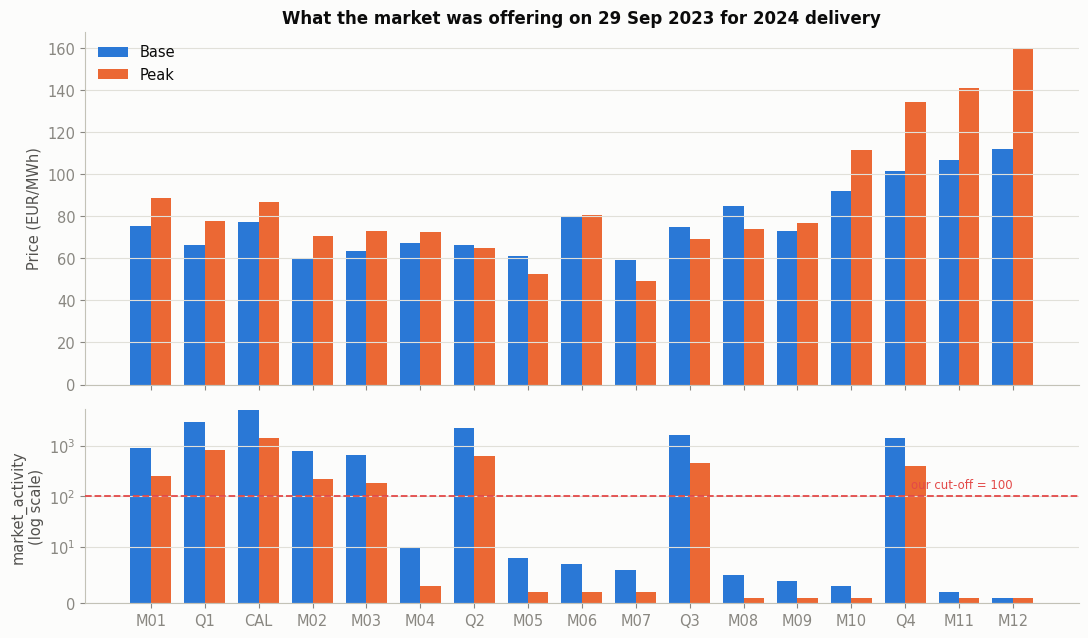

In [10]:
order = fut.drop_duplicates('delivery_period').sort_values('delivery_start')['delivery_period'].tolist()
x     = np.arange(len(order)); width = 0.38

def by_period(load_type, col):
    return fut[fut.load_type == load_type].set_index('delivery_period').reindex(order)[col]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1.1]})

ax1.bar(x - width/2, by_period('BASE', 'price_eur_mwh'), width=width, color=BLUE,   label='Base')
ax1.bar(x + width/2, by_period('PEAK', 'price_eur_mwh'), width=width, color=ORANGE, label='Peak')
ax1.set_ylabel('Price (EUR/MWh)')
ax1.set_title('What the market was offering on 29 Sep 2023 for 2024 delivery')
ax1.legend(loc='upper left'); ax1.grid(axis='x')

ax2.bar(x - width/2, by_period('BASE', 'market_activity'), width=width, color=BLUE)
ax2.bar(x + width/2, by_period('PEAK', 'market_activity'), width=width, color=ORANGE)
ax2.axhline(100, color=RED, linewidth=1.3, linestyle='--', zorder=3)
ax2.annotate('our cut-off = 100', xy=(len(order) - 1, 100), xytext=(0, 6),
             textcoords='offset points', ha='right', color=RED, fontsize=8.5)
ax2.set_yscale('symlog', linthresh=10)
ax2.set_ylabel('market_activity\n(log scale)')
ax2.set_xticks(x); ax2.set_xticklabels(order); ax2.grid(axis='x')

FIGURES['ex2_futures_market'] = fig
plt.tight_layout(); plt.show()

In [11]:
THRESHOLD = 100
fut['usable'] = fut['market_activity'] >= THRESHOLD

liquidity = fut.pivot_table(index='delivery_period', columns='load_type',
                            values='market_activity').reindex(order)
liquidity['tradable?'] = np.where(
    fut.groupby('delivery_period')['usable'].any().reindex(order), 'yes', 'no - too thin')
liquidity

load_type,BASE,PEAK,tradable?
delivery_period,,,
M01,900.00,252.00,yes
Q1,"3,000.00",840.00,yes
CAL,"5,000.00","1,400.00",yes
M02,800.00,224.00,yes
M03,650.00,182.00,yes
M04,10.00,3.00,no - too thin
Q2,"2,200.00",616.00,yes
M05,8.00,2.00,no - too thin
M06,7.00,2.00,no - too thin


In [12]:
# Rather than defending the number 100, test whether the number matters at all.
best = fut.groupby('delivery_period')['market_activity'].max().sort_values(ascending=False)

print('A) SENSITIVITY - does the chosen set depend on where we cut?')
previous = None
for threshold in [1, 2, 3, 5, 8, 11, 100, 651, 900, 1400, 3000, 5000]:
    kept = tuple(sorted(best[best >= threshold].index))
    if kept != previous:
        print(f'   cut at {threshold:>5}  ->  {len(kept):2d} products: {", ".join(kept)}')
        previous = kept

print('\nB) LARGEST-GAP RULE - let the data choose, no threshold at all')
v = best.values.astype(float)
ratios = v[:-1] / v[1:]
k = int(np.argmax(ratios))
for j, (a, b) in enumerate(zip(best.index[:-1], best.index[1:])):
    flag = '   <== biggest break' if j == k else ''
    print(f'   {a:>4} {v[j]:7.0f} -> {b:>4} {v[j+1]:7.0f}   ratio {ratios[j]:5.1f}x{flag}')
print(f'\n   break sits between {best.index[k]} ({v[k]:,.0f}) and {best.index[k+1]} ({v[k+1]:,.0f})')
print(f'   geometric midpoint of that gap = {np.sqrt(v[k] * v[k+1]):.0f}')

print('\nC) DOES THE Base-or-Peak CHOICE MATTER?')
either = set(fut.groupby('delivery_period')['usable'].any().pipe(lambda x: x[x].index))
both   = set(fut.groupby('delivery_period')['usable'].all().pipe(lambda x: x[x].index))
print(f'   qualifying on EITHER leg: {len(either)} products')
print(f'   qualifying on BOTH legs : {len(both)} products')
print(f'   difference              : {either ^ both or "none - the choice is immaterial here"}')

A) SENSITIVITY - does the chosen set depend on where we cut?
   cut at     1  ->  17 products: CAL, M01, M02, M03, M04, M05, M06, M07, M08, M09, M10, M11, M12, Q1, Q2, Q3, Q4
   cut at     2  ->  16 products: CAL, M01, M02, M03, M04, M05, M06, M07, M08, M09, M10, M11, Q1, Q2, Q3, Q4
   cut at     3  ->  15 products: CAL, M01, M02, M03, M04, M05, M06, M07, M08, M09, M10, Q1, Q2, Q3, Q4
   cut at     5  ->  13 products: CAL, M01, M02, M03, M04, M05, M06, M07, M08, Q1, Q2, Q3, Q4
   cut at     8  ->  10 products: CAL, M01, M02, M03, M04, M05, Q1, Q2, Q3, Q4
   cut at    11  ->   8 products: CAL, M01, M02, M03, Q1, Q2, Q3, Q4
   cut at   651  ->   7 products: CAL, M01, M02, Q1, Q2, Q3, Q4
   cut at   900  ->   6 products: CAL, M01, Q1, Q2, Q3, Q4
   cut at  1400  ->   5 products: CAL, Q1, Q2, Q3, Q4
   cut at  3000  ->   2 products: CAL, Q1
   cut at  5000  ->   1 products: CAL

B) LARGEST-GAP RULE - let the data choose, no threshold at all
    CAL    5000 ->   Q1    3000   ratio   1.7x
  

### Which products can we actually use?

**The cut-off — and why the number barely matters.** Look at the bottom chart
(note the log scale): there is a **cliff**, not a slope.

- CAL sits at 5,000. The quarters run 1,400–3,000.
- The first three months, M01–M03, run 650–900.
- Then M04 onwards collapses to **10, 8, 7, 6, 5, 4, 3, 2, 1**.

Rather than argue for a particular threshold, we tested three things.

**A. The answer is invariant.** Sweeping the cut-off from 1 to 5,000 shows the
selected set changes only at the eight values that actually occur. **Every
threshold from 11 to 650 returns exactly the same eight products** — CAL, Q1–Q4
and M01–M03. That is a **59-fold range** over which our choice is irrelevant. So
we are not defending the number 100; we are pointing out that no defensible
number would change the outcome.

**B. The data can choose for itself.** Ranking the products and looking at the
ratio between neighbours, the biggest break is **65x**, between M03 (650) and M04
(10). The next largest break anywhere in the list is **2.0x**. The cliff is not
one candidate among several — it is unmistakable. A parameter-free "largest gap"
rule puts the cut at a geometric midpoint of **81**, which is essentially the 100
we chose by eye.

**C. Base or Peak?** Our rule accepts a product if **either** leg clears the bar.
Peak activity always runs at about 28% of Base, so in principle a product could
qualify on its Base leg alone. It does not happen here: the thinnest qualifying
Peak leg is M03 at 182, comfortably clear. Requiring **both** legs gives the
identical set, so this modelling choice is immaterial — worth stating rather than
leaving unexamined.

**Conclusion:** tradable = **CAL, Q1, Q2, Q3, Q4, M01, M02, M03**. Illiquid and
excluded = **M04–M12**. Nothing sits near the boundary.

**Tradable:** CAL, Q1, Q2, Q3, Q4, M01, M02, M03.
**Too illiquid to use:** M04 through M12.

This pattern is realistic. In September 2023 traders were actively quoting the
year, the quarters, and the next few months. Nobody was seriously trading
individual months a year ahead — those quotes exist on the screen, but you could
not fill a real order at them.

### Ways of covering 2024 without double-buying

A hedge has to cover every delivery hour of 2024 **exactly once**. Using only the
tradable products, there are three sensible ways:

| Set | Products | How fine |
|---|---|---|
| **CAL** | 1 × Base + 1 × Peak | Coarse — one price for the whole year |
| **Q1 + Q2 + Q3 + Q4** | 4 × 2 | Medium — follows the seasons |
| **M01 + M02 + M03 + Q2 + Q3 + Q4** | 6 × 2 | Finest possible — monthly detail where the market allows it, quarterly after that |

The third set is the interesting one. We *want* monthly detail all year, but the
market will not give it to us after March. So we take the finest granularity
liquidity permits, then fall back to quarters. That is a real trading constraint
shaping a real strategy.

### Why we cannot just buy everything

Suppose we bought CAL **and** all four quarters at full volume. January would
then be covered twice — once by CAL, once by Q1. We would be holding roughly
**86,000 MWh** of position against a **43,000 MWh** book.

That is no longer a hedge; it is a bet. And it wrecks the comparison we are
trying to make. The point of comparing CAL against the granular set is to ask
*"does finer granularity fit our load shape better?"* If one set also carries
double the volume, we are measuring **position size**, not **shape quality** —
two completely different questions. Same reason a quarter cannot be combined
with its own months.

### The seasonal pattern in the prices

Two things stand out in the top chart:

**Winter is expensive.** Q4 Base is **€101.39** against Q2's **€66.23** — more than
50% higher. M11 and M12 are higher still (€106.66 and €112.07). Cold, dark, and
little solar. This is bad news for us specifically, because Q4 is also when our
customers use the most electricity: our **biggest volumes land in the priciest
block**.

**The Peak premium changes sign with the season.** Normally daytime power costs
more than nighttime, and in winter it does — Q4 Peak (€134.42) is €33 above Q4
Base. But in **Q2 and Q3 the Peak price is *below* Base** (€64.76 vs €66.23, and
€69.07 vs €74.74). Summer solar floods the middle of the day and pushes daytime
prices *below* the round-the-clock average. The market was pricing this a year
in advance.

---
# Exhibit 3 — Historical price shape

**File:** `shape_factors.csv`, built from four years of real Day-Ahead prices
(2019–2022).

### What a shape factor is

It is **not a price**. It is a multiplier — a number saying how expensive an hour
usually is compared with the year's average. The whole set is scaled so the
annual average comes to exactly **1.00**.

- **Above 1** → that hour normally costs *more* than the yearly average.
  A factor of 1.30 means "about 30% above average".
- **Below 1** → that hour normally costs *less*. 0.80 means "about 20% below".
- **Exactly 1** → an average hour.

Every one of the 35,136 quarter-hours of 2024 gets a factor, based on which
**month**, **hour**, and **weekday** it falls in. All four quarter-hours inside an
hour share the same value, because the pattern was measured hourly.

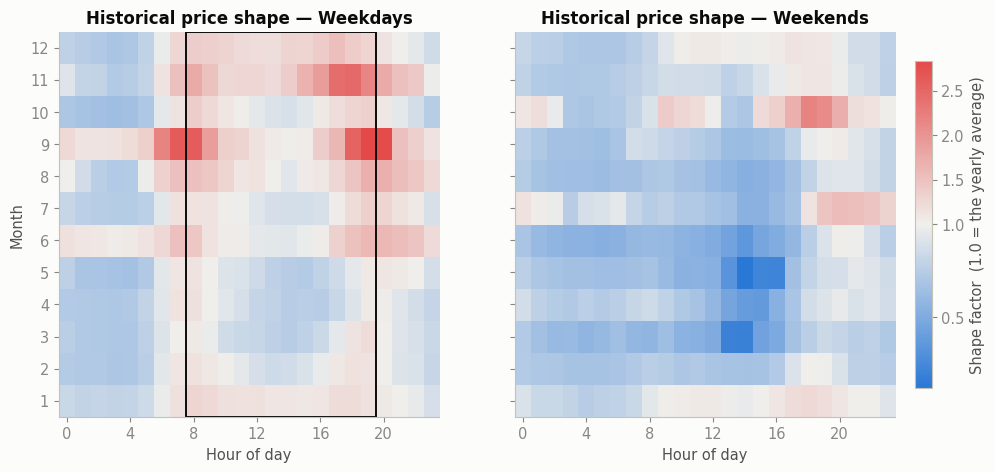

In [13]:
shp = pd.read_csv(f'{DATA}/shape_factors.csv')
shp['is_weekend'] = shp['weekday'] >= 5
s = shp['historical_shape_factor']

def month_hour_pivot(df):
    return df.pivot_table(index='month', columns='hour',
                          values='historical_shape_factor', aggfunc='mean')

pivot_wd = month_hour_pivot(shp[~shp.is_weekend])
pivot_we = month_hour_pivot(shp[shp.is_weekend])

norm = TwoSlopeNorm(vmin=min(pivot_wd.min().min(), pivot_we.min().min()),
                    vcenter=1.0,
                    vmax=max(pivot_wd.max().max(), pivot_we.max().max()))
cmap = LinearSegmentedColormap.from_list('div_blue_red', [BLUE, GRAY, RED])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, pivot, title in zip(axes, [pivot_wd, pivot_we], ['Weekdays', 'Weekends']):
    im = ax.imshow(pivot.values, aspect='auto', cmap=cmap, norm=norm, origin='lower')
    ax.set_title(f'Historical price shape — {title}')
    ax.set_xlabel('Hour of day')
    ax.set_xticks(range(0, 24, 4)); ax.set_xticklabels(range(0, 24, 4))
    ax.set_yticks(range(12)); ax.set_yticklabels(range(1, 13))
    ax.grid(False)
    if title == 'Weekdays':
        ax.axvspan(7.5, 19.5, edgecolor=INK, facecolor='none', linewidth=1.4)
axes[0].set_ylabel('Month')
cbar = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02)
cbar.set_label('Shape factor  (1.0 = the yearly average)')
FIGURES['ex3_price_shape'] = fig
plt.show()

In [14]:
print(f"Average over ALL hours                  : {s.mean():.4f}   (1.00 by construction)")
print(f"Average over Peak hours (Mon-Fri 08-20) : {s[shp.is_peak == 1].mean():.3f}")
print(f"Average over all other hours            : {s[shp.is_peak == 0].mean():.3f}")
print(f"Average over weekdays                   : {s[~shp.is_weekend].mean():.3f}")
print(f"Average over weekends                   : {s[shp.is_weekend].mean():.3f}")
print(f"\nCheapest hour in the table              : {s.min():.3f}")
print(f"Most expensive hour in the table        : {s.max():.3f}   ({s.max()/s.min():.0f}x the cheapest)")

flat = pivot_wd.stack().sort_values()
print('\nCheapest weekday month-hours:')
for (m, h), v in flat.head(3).items():
    print(f"   month {int(m):2d}, {int(h):02d}:00  ->  {v:.2f}")
print('Most expensive weekday month-hours:')
for (m, h), v in flat.tail(3).items():
    print(f"   month {int(m):2d}, {int(h):02d}:00  ->  {v:.2f}")

# where exactly are the cheap and dear regions? average a few blocks
blocks = {
    'Night 01-05h (all months)':      pivot_wd.loc[:, 1:5].mean().mean(),
    'Midday 12-15h, Mar-May':         pivot_wd.loc[3:5, 12:15].mean().mean(),
    'Midday 12-15h, Jun-Aug':         pivot_wd.loc[6:8, 12:15].mean().mean(),
    'Evening 17-19h, Jan-Feb':        pivot_wd.loc[1:2, 17:19].mean().mean(),
    'Evening 17-19h, Nov-Dec':        pivot_wd.loc[11:12, 17:19].mean().mean(),
    'Evening 17-19h, September':      pivot_wd.loc[9, 17:19].mean(),
    'WEEKEND midday 12-15h, Mar-May': pivot_we.loc[3:5, 12:15].mean().mean(),
}
print('\nAverage factor in selected blocks (weekdays unless stated):')
for k, v in blocks.items():
    print(f"   {k:<32s} {v:.2f}")

Average over ALL hours                  : 1.0000   (1.00 by construction)
Average over Peak hours (Mon-Fri 08-20) : 1.167
Average over all other hours            : 0.907
Average over weekdays                   : 1.080
Average over weekends                   : 0.799

Cheapest hour in the table              : 0.122
Most expensive hour in the table        : 2.838   (23x the cheapest)

Cheapest weekday month-hours:
   month 10, 03:00  ->  0.64
   month 10, 02:00  ->  0.66
   month 10, 04:00  ->  0.66
Most expensive weekday month-hours:
   month  9, 07:00  ->  2.63
   month  9, 20:00  ->  2.79
   month  9, 19:00  ->  2.84

Average factor in selected blocks (weekdays unless stated):
   Night 01-05h (all months)        0.81
   Midday 12-15h, Mar-May           0.78
   Midday 12-15h, Jun-Aug           0.96
   Evening 17-19h, Jan-Feb          1.15
   Evening 17-19h, Nov-Dec          1.87
   Evening 17-19h, September        2.33
   WEEKEND midday 12-15h, Mar-May   0.37


### Reading the heatmap

**Red means expensive, blue means cheap, grey is average.** Months run up the
side, hours run across.

**The cheap hours: night, and spring afternoons.** The night block, 01:00–05:00,
averages **0.81** across all months — demand is low and whatever is running keeps
running. The cheapest weekday cell in the table is an October 03:00 at **0.64**.

But the deepest blue on the map is not the night. It is **spring midday**.
March–May, 12:00–15:00, averages **0.78** on weekdays — *cheaper than the middle
of the night*. And notice it is cheaper than **summer** midday (June–August:
**0.96**), which is not what most people would guess. Spring is the sweet spot for
the German grid: solar output is already strong, but nobody is heating any more
and nobody is running air conditioning yet. Summer keeps more daytime demand, so
prices do not fall as far.

On weekends the effect becomes extreme. March–May weekend middays average
**0.37**, and the single cheapest cell in the whole table is a **May weekend at
14:00, factor 0.12** — 88% below the yearly average. A sunny Sunday afternoon in
May with the factories shut is the cheapest electricity Germany produces.

**The expensive hours: the morning ramp and the evening peak.** Roughly
07:00–09:00 and 17:00–20:00, when people are awake and solar is not helping.

**But look at *which months* are reddest — this is the surprise.** It is not
January. It is **September** (weekday evenings **2.33**, mornings **2.38**) and
**November** (evenings **2.35**). Meanwhile January and February evenings only
reach **1.15**.

That is backwards. The coldest, darkest months should be the dearest, and here
they are among the mildest. The explanation is not seasonal at all: it is the
**2021–22 European gas crisis**. Autumn 2021 and autumn 2022 saw historically
extreme power prices, and those months sit inside this 2019–2022 average, hauling
September and November far above where a normal year would put them.

This is the most important caveat in the whole briefing. The "historical shape"
is not a typical year — it is three fairly ordinary years plus one extraordinary
one, averaged together. *Consequence for the main project:* our hourly curve will
**overstate September and November prices** and understate how much deep-winter
evenings really matter. We use it anyway, because it is the shape the brief
provides, but the recommendation should say so out loud.

**Does the Peak definition match reality?** Yes — worth checking rather than
assuming. The black box on the left panel is the contractual Peak window, Mon–Fri
08:00–20:00, and it does land on the warm part of the map:

- Peak hours average **1.167**
- Every other hour averages **0.907**

So the product genuinely captures the expensive part of the day. Not perfectly —
the box swallows those cheap spring middays and cuts off the winter evening ramp
after 20:00 — but as a blunt instrument it works.

**Weekdays and weekends are very different.** Weekdays average **1.080**, weekends
**0.799**: weekend power is about **26% cheaper**. The right panel is paler almost
everywhere. Inside the very same 08:00–20:00 hours, weekdays average **1.171**
and weekends only **0.799**.

This is exactly why Peak futures are defined to exclude weekends — you should not
pay a daytime premium for a Saturday. But it also sharpens the problem Exhibit 1
found: our customers still consume **28.5%** of their energy at weekends, and no
Peak product will ever shape a single hour of it.

### What the shape adds to a futures quote

A futures price is a single number for an enormous block of time. The Q3 Base
quote of **€74.74** covers all 8,832 quarter-hours of the third quarter — one
number, no detail.

But we do not consume evenly, and prices are not flat. To value our portfolio we
need a price for *every* quarter-hour. The shape factor is what gets us there:

```
                                        shape factor of that hour
hourly price  =  block price  x  --------------------------------------
                                  average shape factor over the block
```

Dividing by the block's own average is the trick that makes this safe. It forces
the rescaled factors to average exactly 1 within the block, so **the block still
averages to the quoted price**. We redistribute value across hours without
creating or destroying any.

**What it adds:** relative structure inside the block — which hours are dear,
which are cheap. Information the futures market simply does not quote.

**What it does not add:** any new view on the price level. The market sets that.
And it is **not a forecast**. It says how a block price should be spread across
hours; it says nothing about what any particular hour in 2024 will actually cost.
It is four years old and knows nothing about 2024's weather.

---
# Exhibit 4 — What actually happened in 2024

**Files:** `day_ahead_prices.csv` and `imbalance_prices.csv`.

These are the two prices we will really pay. They work very differently:

**Day-Ahead** is an auction that closes the day before delivery. We forecast what
our customers will need, we buy it, and we see the price before committing. It is
a market we choose to enter.

**Imbalance (reBAP)** is not a market at all. If our customers use more than we
bought, the grid operator covers the difference and bills us afterwards at
whatever reBAP turns out to be. If they use less, we are paid for the surplus at
that price. We do not see it in advance and we cannot opt out. It is designed to
be uncomfortable, because its job is to make everyone forecast honestly.

In [15]:
mkt = pd.merge(da[['timestamp_utc', 'timestamp_local', 'day_ahead_price_eur_mwh']],
               imb[['timestamp_utc', 'imbalance_price_eur_mwh']], on='timestamp_utc')
mkt['timestamp_local'] = to_local(mkt['timestamp_local'])

stats = pd.DataFrame({
    'Day-Ahead':         mkt['day_ahead_price_eur_mwh'].describe(percentiles=[.01, .5, .99]),
    'Imbalance (reBAP)': mkt['imbalance_price_eur_mwh'].describe(percentiles=[.01, .5, .99]),
})
stats.loc['% of intervals negative'] = [
    (mkt['day_ahead_price_eur_mwh'] < 0).mean() * 100,
    (mkt['imbalance_price_eur_mwh'] < 0).mean() * 100,
]
stats

,Day-Ahead,Imbalance (reBAP)
count,"35,136.00","35,136.00"
mean,78.51,85.77
std,52.72,282.66
min,-135.45,"-5,734.46"
1%,-19.99,-175.64
50%,79.59,89.95
99%,224.92,447.85
max,936.28,"14,999.99"
% of intervals negative,5.20,19.81


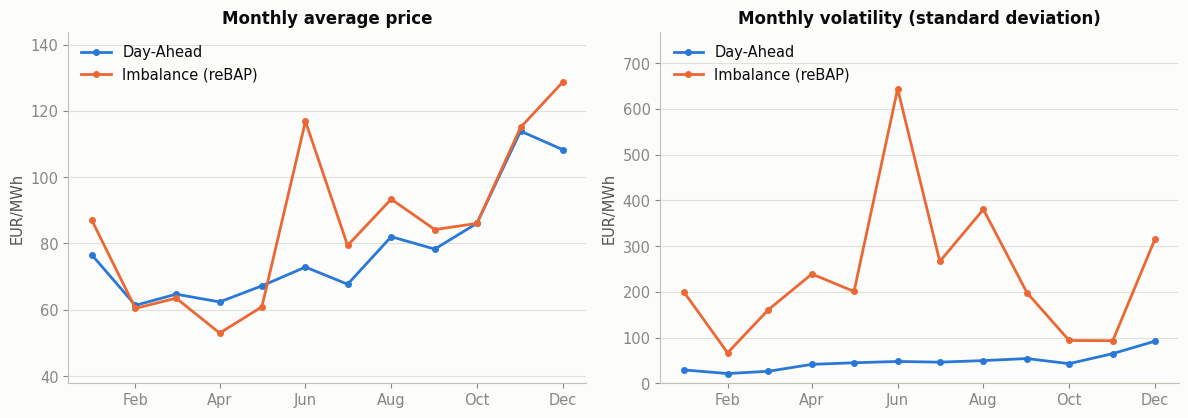

In [16]:
monthly = (mkt.set_index('timestamp_local')[['day_ahead_price_eur_mwh', 'imbalance_price_eur_mwh']]
              .resample('MS').agg(['mean', 'std']))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(monthly.index, monthly[('day_ahead_price_eur_mwh', 'mean')], color=BLUE,
         linewidth=2, marker='o', markersize=4, label='Day-Ahead')
ax1.plot(monthly.index, monthly[('imbalance_price_eur_mwh', 'mean')], color=ORANGE,
         linewidth=2, marker='o', markersize=4, label='Imbalance (reBAP)')
ax1.set_title('Monthly average price'); ax1.set_ylabel('EUR/MWh')

ax2.plot(monthly.index, monthly[('day_ahead_price_eur_mwh', 'std')], color=BLUE,
         linewidth=2, marker='o', markersize=4, label='Day-Ahead')
ax2.plot(monthly.index, monthly[('imbalance_price_eur_mwh', 'std')], color=ORANGE,
         linewidth=2, marker='o', markersize=4, label='Imbalance (reBAP)')
ax2.set_title('Monthly volatility (standard deviation)'); ax2.set_ylabel('EUR/MWh')

for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.legend(loc='upper left'); ax.grid(axis='x'); ax.margins(y=0.2)
ax2.set_ylim(bottom=0)

FIGURES['ex4_prices'] = fig
plt.tight_layout(); plt.show()

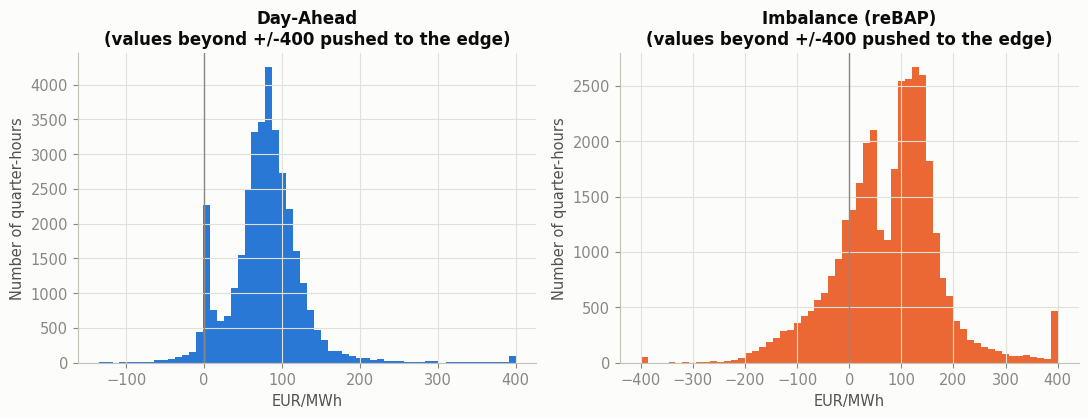

reBAP intervals outside +/-400 EUR/MWh : 489 of 35,136 (1.39%)
Same for Day-Ahead                       : 100


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
clip = 400
for ax, col, color, title in zip(axes,
        ['day_ahead_price_eur_mwh', 'imbalance_price_eur_mwh'], [BLUE, ORANGE],
        ['Day-Ahead', 'Imbalance (reBAP)']):
    ax.hist(mkt[col].clip(-clip, clip), bins=60, color=color)
    ax.axvline(0, color=INK_MUTE, linewidth=1)
    ax.set_title(f'{title}\n(values beyond +/-{clip} pushed to the edge)')
    ax.set_xlabel('EUR/MWh'); ax.set_ylabel('Number of quarter-hours')
FIGURES['ex4_distributions'] = fig
plt.tight_layout(); plt.show()

beyond = (mkt['imbalance_price_eur_mwh'].abs() > clip).sum()
print(f"reBAP intervals outside +/-{clip} EUR/MWh : {beyond} of {len(mkt):,} ({beyond/len(mkt)*100:.2f}%)")
print(f"Same for Day-Ahead                       : {(mkt['day_ahead_price_eur_mwh'].abs() > clip).sum()}")

In [18]:
cols = ['timestamp_local', 'day_ahead_price_eur_mwh', 'imbalance_price_eur_mwh']
print('The 5 most expensive reBAP intervals of 2024:')
print(mkt.nlargest(5, 'imbalance_price_eur_mwh')[cols].to_string(index=False))
print('\nThe 5 most negative reBAP intervals of 2024:')
print(mkt.nsmallest(5, 'imbalance_price_eur_mwh')[cols].to_string(index=False))
print('\nThe 5 most expensive Day-Ahead intervals of 2024:')
print(mkt.nlargest(5, 'day_ahead_price_eur_mwh')[cols].to_string(index=False))

The 5 most expensive reBAP intervals of 2024:
          timestamp_local  day_ahead_price_eur_mwh  imbalance_price_eur_mwh
2024-06-03 09:00:00+02:00                   128.08                14,999.99
2024-06-03 08:00:00+02:00                   164.48                14,129.27
2024-08-26 19:45:00+02:00                   190.31                13,194.36
2024-06-03 09:30:00+02:00                   128.08                12,125.64
2024-06-03 09:45:00+02:00                   128.08                11,871.49

The 5 most negative reBAP intervals of 2024:
          timestamp_local  day_ahead_price_eur_mwh  imbalance_price_eur_mwh
2024-04-07 14:15:00+02:00                   -20.06                -5,734.46
2024-04-10 15:30:00+02:00                    55.35                -4,599.81
2024-06-28 14:00:00+02:00                    -9.95                -3,518.42
2024-12-19 04:00:00+01:00                     0.31                -3,226.21
2024-04-07 14:00:00+02:00                   -20.06                -3,185

### Reading the results

**The averages look almost identical. Ignore them.** Day-Ahead averaged
**€78.51/MWh** and reBAP **€85.77/MWh**. If you stopped there you would conclude
the two prices are much the same. They are not.

**Spread is the whole story.**

| | Day-Ahead | reBAP |
|---|---|---|
| Standard deviation | €52.72 | **€282.66** (5× wider) |
| Lowest | −€135.45 | **−€5,734.46** |
| Highest | €936.28 | **€14,999.99** |
| Middle 98% of values | −€20 to €225 | −€176 to €448 |
| Negative intervals | 5.2% | **19.8%** |

Day-Ahead behaves. reBAP does not: its worst spike is **16 times** higher than
Day-Ahead's, and its worst crash **42 times** deeper. One in five reBAP intervals
is negative — meaning if you were short at the wrong moment you were paid to
consume, and if you were long you paid someone to take power off your hands.

The histograms show it too. Day-Ahead is a recognisable bell shape. reBAP is
spiky: **489 intervals (1.39%)** fall outside ±€400 and had to be pushed to the
chart edges to keep the picture readable, against **100** for Day-Ahead — nearly
five times as many, and reBAP's go vastly further out.

**When was volatility high?** The right-hand chart answers this, and it is not
uniform across the year:

- **Day-Ahead volatility climbs steadily** from €21 in February to **€92 in
  December** — winter scarcity, with December combining the highest average
  (€108) and the widest swings.
- **Spring and summer bring negative prices**, not high ones. July and May had
  the most negative Day-Ahead intervals (~11% each), against ~1–2% in winter.
  Too much solar, too little demand.
- **reBAP volatility spikes in June** at **€644** — more than double any other
  month — even though June's Day-Ahead was unremarkable. That single month is
  worth investigating on its own.

**Is reBAP more variable than Day-Ahead?** Yes, in every month of the year and by
a factor of 3 to 7. This is the empirical backbone of the whole project: futures
protect the **price** of the load we forecast, but any volume we get **wrong**
settles against this much wilder series.

### The episode worth investigating

Two candidates, and they fail in opposite directions:

**3 June 2024, 08:00–10:00.** Day-Ahead was calm at €128–164/MWh. reBAP hit
**€14,999.99/MWh** — the cap — for several quarter-hours in a row. The two prices
came completely apart. This is a **real-time balancing crisis**: something in the
system went wrong after the Day-Ahead auction had already closed. No futures
position and no clever Day-Ahead scheduling protects you, because both are based
on the **forecast**. Only being accurate helps. It also explains June's €644
volatility.

**12 December 2024, 17:00–20:00.** The mirror image. Day-Ahead itself spiked to
**€936.28/MWh** — a genuine winter evening shortage, a dark and windless
weekday evening — while reBAP stayed relatively tame at €90–185. This is a pure
**price event**, and it is exactly the thing futures exist to protect against. It
also justifies why Q4 and December were quoted at such a premium a year earlier.

Both belong in the main project's severe-price-event analysis. One tests what the
hedge **can** protect (price), the other tests what it **cannot** (volume).

---
# Closing the briefing

### 1. What did we know on 29 September 2023, and what only later?

This distinction decides what is allowed to influence the hedge decision.

**Known when the hedge was designed:**
- The customer table — how many customers, how much each uses per year.
- The standard load profiles from Stromnetz Berlin, published in advance.
- The futures quotes and their `market_activity` — the snapshot itself is dated
  29 September 2023.
- The historical price shape, built from 2019–2022 data.

**Only known during delivery:**
- Realised 2024 Day-Ahead prices.
- Realised 2024 reBAP.
- What customers actually consumed.

The rule that follows: the second group may be used to **judge** the hedge
afterwards, never to **choose** it. Picking Q4 futures because we know December
2024 spiked is not analysis, it is hindsight. Our hedge must be defensible using
only the first list.

### 2. What did we check before trusting any of this?

- **Row counts and alignment.** All six files carry 35,136 rows on the same
  15-minute grid.
- **Units.** Each SLP column sums to 1,000,000 — kWh, not MWh. Missing this
  would have made the portfolio 1,000× too large.
- **Reconciliation.** After scaling, each group's annual energy matches the
  customer table exactly. This is also our clock-change check.
- **The clock changes themselves.** 31 March has 92 quarter-hours, 27 October has
  100. Present and correct, so we count intervals from the real grid rather than
  from the calendar.
- **Day-Ahead granularity.** Confirmed hourly — all 8,784 hours have four
  identical quarter-values. reBAP is genuinely quarter-hourly.
- **The liquidity break is real, not invented.** A 65× cliff between M03 and M04,
  with nothing near our threshold.
- **The shape factor averages 1.00** and its Peak-hour pattern lines up with the
  contractual Peak window — the two definitions agree.
- **Cross-checked the price extremes against each other.** The biggest reBAP
  spikes and the biggest Day-Ahead spikes happen on *different* days, which is
  itself the finding. Neither series was accepted on its own.

### 3. What would a real portfolio still be missing?

At least six things this simplified case leaves out. The three that would move
the answer most:

**a) Customers leave.** We assume a fixed 10,220 customers all year. In reality
people switch supplier constantly — German retail churn runs at a few percent a
year. *Effect:* we would be over-hedged. Futures cannot be undone without selling
them back, so churn turns a hedge into an accidental long position sold into
whatever the market offers later. Direction depends on prices, but the **risk is
real and one-sided**: we would discover it during delivery, not before.

**b) The forecast is a fixed profile with no weather in it.** A standard load
profile does not know that February 2024 was mild. *Effect:* a systematic,
correlated error — cold snaps make everyone under-forecast **at the same time**,
which is exactly when reBAP is most punishing. Our forecast errors would not be
random noise; they would cluster on the worst days.

**c) Trading is free and infinitely divisible here.** No bid-ask spread, no fees,
no minimum contract size — the brief says so explicitly. *Effect:* the granular
hedge is flattered. It uses six products where CAL uses one, so it crosses the
spread six times and gets rounded to whole lots six times. In reality some of its
shape advantage would be eaten by costs, and the gap between the two strategies
would narrow.

**Three more worth naming:**

**d) No holiday calendar.** 1 January 2024 is labelled a normal Monday with Peak
hours from 08:00. Real holidays price like Sundays. *Effect:* our curve
overstates prices on roughly ten days a year.

**e) The historical shape carries the 2021–22 gas crisis.** September and
November are the reddest months on the heatmap (evening factors of 2.33 and 2.35)
while January and February only reach 1.15. That ordering is not seasonal — it is
one extraordinary autumn sitting inside a four-year average. *Effect:* the curve
overstates September and November, and understates how much deep-winter evenings
should matter. Since Q4 is both our highest-volume and highest-priced block, this
distortion lands exactly where the hedge decision is most sensitive.

**f) No counterparty or credit risk.** A future is a promise from someone else,
and holding one requires posting margin when prices move. *Effect:* a hedge that
looks costless on paper can create real cash-flow strain — which matters
precisely during the extreme events we are hedging against.

---
---
# PART 2 — Main Project

### The decision we are being asked to make

It is **29 September 2023**. We supply 10,220 customers in Berlin and we have to
buy their 2024 electricity. Our manager wants a recommendation: **how should we
buy it?**

Prices could rise, and if they do we cannot simply raise our customers' prices —
we sold them a fixed deal. So we want to lock prices in now. The trouble is that
the market only sells **blocks** (a whole year, a quarter, a month) at a **flat
rate**, while our customers use electricity in an uneven, wobbly pattern. That
mismatch creates two problems the brief names directly:

- **Shape risk** — the block we buy does not match the shape of what we sell.
- **Volume risk** — customers will not use exactly what we forecast.

### How the money actually flows

Buying happens in three layers, and each one settles at a different price:

| Layer | What it does | Price we pay |
|---|---|---|
| **1. Futures** | Locks a price for big blocks, months in advance | Fixed on 29 Sep 2023 |
| **2. Day-Ahead** | Buys whatever the futures did not cover | Realised Day-Ahead |
| **3. Imbalance** | Settles the difference between forecast and reality | Realised reBAP |

We only control the first two. The third is charged to us afterwards whether we
like it or not.

### The three strategies we compare

| Strategy | Which futures it uses |
|---|---|
| **UNHEDGED** | None. Buy everything on the day. The benchmark. |
| **COARSE_CAL** | The annual product only — CAL Base + CAL Peak. |
| **GRANULAR** | The finest tradable non-overlapping set: M01 + M02 + M03 + Q2 + Q3 + Q4, Base and Peak. |

The product choice is not handed to us — we justified it in the data briefing
using `market_activity`, and Stage 3 shows both hedges cover 2024 exactly once.

The product choice is not handed to us — Exhibit 2 justified it with
`market_activity`, and Stage 3 shows both hedges cover 2024 exactly once.

---
# Stage 1 — Forecast the customer portfolio

**Inputs:** the customer table and `slp_profiles.csv`.

> **The brief asks:** *"Construct the quarter-hourly forecast load of each
> customer group and the total portfolio... Reconcile the resulting annual energy
> with the customer table and distinguish correctly between quarter-hourly MWh
> and average MW. Explain how the customer mix affects the daily and seasonal
> load shape and the potential use of Base and Peak futures."*

**Exhibit 1 already did this work**, so here we simply carry the result forward
and answer the questions the main brief asks. The construction was:

```
Step 1     E_p = n_p x e_p              how much energy the group needs

                          s_p,t
Step 2     L_p,t = E_p x ---------      spread it over the year using the profile
                         sum(s_p)

Step 3     L_t = sum over p of L_p,t    add the three groups together
```

The middle fraction is just *"what share of the year's energy falls in this
quarter-hour"*. It is a single constant applied to all 35,136 intervals, so it
changes the **level** but never the **shape**.

In [19]:
# Exhibit 1 already scaled and reconciled the portfolio - reuse it rather than
# doing the same arithmetic twice. Everything downstream depends on L.
load = portfolio                         # already scaled and reconciled above
L    = load['total_mwh'].values          # the forecast load, MWh per quarter-hour
CCOL = COLORS                            # keep Exhibit 1's colour assignment

summary[['profile', 'customers', 'MWh each', 'scaling factor',
         'annual MWh target', 'annual MWh after scaling', 'difference', 'share %']]

,profile,customers,MWh each,scaling factor,annual MWh target,annual MWh after scaling,difference,share %
0,Household (HB),10000,3.50,35.00,"35,000.00","35,000.00",0.00,81.40
1,General commercial (GB),200,30.00,6.00,"6,000.00","6,000.00",-0.00,13.95
2,Agriculture (LB),20,100.00,2.00,"2,000.00","2,000.00",0.00,4.65


In [20]:
hours = len(load) * DT_H
load['hour']       = load['timestamp_local'].dt.hour + load['timestamp_local'].dt.minute / 60
load['is_weekend'] = load['timestamp_local'].dt.weekday >= 5
load['month']      = load['timestamp_local'].dt.month

print(f"Total annual energy   : {L.sum():,.1f} MWh")
print(f"Average load          : {L.sum() / hours:,.2f} MW")
print(f"Highest quarter-hour  : {L.max() / DT_H:,.2f} MW")
print(f"Lowest quarter-hour   : {L.min() / DT_H:,.2f} MW")
print(f"Load factor (avg/peak): {(L.mean() / L.max()):.1%}")

pk_mask = (~load.is_weekend) & (load.hour >= 8) & (load.hour < 20)
print(f"\nEnergy inside the Peak window : {L[pk_mask].sum() / L.sum():.1%}")
print(f"Share of the year that IS Peak: {pk_mask.mean():.1%}")
print(f"Energy used at weekends       : {L[load.is_weekend.values].sum() / L.sum():.1%}")

monthly_mw = load.groupby('month')['total_mwh'].sum() / (load.groupby('month').size() * DT_H)
print(f"\nBusiest month : {monthly_mw.idxmax():>2}  ({monthly_mw.max():.2f} MW, "
      f"{monthly_mw.max()/(L.sum()/hours)-1:+.0%} vs the annual average)")
print(f"Quietest month: {monthly_mw.idxmin():>2}  ({monthly_mw.min():.2f} MW, "
      f"{monthly_mw.min()/(L.sum()/hours)-1:+.0%} vs the annual average)")

Total annual energy   : 43,000.0 MWh
Average load          : 4.90 MW
Highest quarter-hour  : 10.40 MW
Lowest quarter-hour   : 1.68 MW
Load factor (avg/peak): 47.1%

Energy inside the Peak window : 44.5%
Share of the year that IS Peak: 35.8%
Energy used at weekends       : 28.5%

Busiest month :  1  (5.73 MW, +17% vs the annual average)
Quietest month:  7  (4.14 MW, -15% vs the annual average)


## Stage 1 — answers

### Q: Does the annual energy reconcile with the customer table?

**Yes, exactly.** The `difference` column is zero for all three groups:
35,000 + 6,000 + 2,000 = **43,000 MWh**.

This check is not a formality. Between the target and the reconstructed total sit
a 35,136-interval grid and two clock changes — 31 March has only 92 quarter-hours,
27 October has 100. If those had been mishandled the difference would not be
zero. The reconciliation is really a **test of the time handling**.

### Q: MWh or MW — what is the difference and why does it matter?

A quarter-hour is a quarter of an hour, so `MW = MWh / 0.25`. Confusing them
costs a factor of four.

| | |
|---|---|
| Energy sold over the year | **43,000 MWh** |
| Average load if it ran flat | **4.90 MW** |
| Highest quarter-hour | **10.40 MW** |
| Lowest quarter-hour | **1.68 MW** |
| Load factor | **47%** |

The busiest moment draws more than six times the quietest. **Futures are sold in
MW; customers are measured in MWh.** Stage 3 buys MW and must be compared against
MWh — so every number below keeps the two apart deliberately.

### Q: How does the customer mix affect the load shape?

**Households set the character.** HB is 81.4% of the energy, GB 14.0%, LB 4.7%,
so the portfolio essentially *is* a household, with texture added on top:

- **HB** is the most volatile profile: a morning ramp near 07:00, a deep
  overnight trough, and a strong evening peak around 19:00–20:00.
- **GB** adds a business-hours plateau — flatter, and only a seventh of the book.
- **LB** is nearly flat and too small to move the total.

**Daily:** a double hump — morning and evening — with the evening one larger.

**Seasonal:** January runs **+17%** above the annual average, July **−15%** below
— a roughly 30% winter-to-summer swing driven by heating and lighting.

### Q: What does this mean for using Base and Peak futures?

**Peak earns its place.** 44.5% of our energy falls inside the Peak window, which
is only 35.8% of the year's hours. We are about **1.24× daytime-weighted**, so a
Peak position genuinely buys power where we need more of it.

**But Base and Peak can never finish the job.** Two structural gaps, both visible
in the Exhibit 1 charts:

1. **The evening peak runs past 20:00**, exactly where the Peak product stops
   delivering. Our single largest daily peak is only half covered.
2. **28.5% of our energy is used at weekends**, when Peak delivers nothing at
   all — and the weekend curve is not flat. Between roughly 09:00 and 15:00
   weekend load actually **exceeds** weekday load, because people are home. Our
   highest daytime demand sits exactly where no Peak product can reach.

**The seasonal swing argues for granularity**, and it also concentrates our risk
badly: Q4 is simultaneously our **highest-volume quarter** and the **most
expensive block quoted** (€101.39/MWh Base against €77.26 for the year). Our
largest volumes land in the priciest period — which is precisely why Stage 3's
choice of granularity matters.

---
# Stage 2 — Build the hourly price curve (HPFC)

**Inputs:** `futures_prices.csv` and `shape_factors.csv`.

> **The brief asks:** *"Construct a simplified Hourly Price Forward Curve...
> Conclude this stage by explaining why a contract-consistent HPFC is useful for
> valuation but is not a forecast of realised Day-Ahead prices."*

### Why we need this at all

Stage 3 has to decide how many MW of each future to buy. To do that it must
compare **the value of what we sell** against **the value of what we buy** — and
value means price × volume, hour by hour.

But the market quotes only block averages. The Q3 Base quote of €74.74 covers all
8,832 quarter-hours of the third quarter as one number. We need a price for
*every* quarter-hour.

The HPFC builds one from two ingredients that never mix:

- **The futures decide the price level.** Market information; we do not touch it.
- **The historical shape decides the pattern inside the block.** It says which
  hours are dear and which are cheap, but never how expensive the block is.

We build it on the **GRANULAR** product set — M01, M02, M03, Q2, Q3, Q4 — because
that is the finest tradable set, so it carries the most market information.

### Step 1 — work out the Off-Peak price

The market quotes Base and Peak, but not Off-Peak. We need Off-Peak because we
want to shape day and night separately.

Base is the average over **all** hours; Peak is the average over **Peak** hours
only. So the Base average must equal the Peak and Off-Peak averages blended by
how many hours each covers:

```
P_base x N_all  =  P_peak x N_peak  +  P_off x N_off

rearranged:

           (P_base x N_all)  -  (P_peak x N_peak)
P_off  =  -----------------------------------------
                          N_off

N_all  = all quarter-hours in the period
N_peak = the Peak ones (Mon-Fri 08:00-20:00)
N_off  = everything else
```

We count `N_all`, `N_peak` and `N_off` **from the real grid**, not from the
calendar — because of the clock changes.

In [21]:
shape = pd.read_csv(f'{DATA}/shape_factors.csv')
shape['timestamp_local'] = to_local(shape['timestamp_local'])

# the supplied is_peak flag is the contractual Peak definition - verify, don't assume
_wd, _h = shape['timestamp_local'].dt.weekday, shape['timestamp_local'].dt.hour
assert (((_wd < 5) & (_h >= 8) & (_h < 20)).astype(int) == shape['is_peak']).all()
assert (shape['timestamp_local'].values == load['timestamp_local'].values).all()
print('is_peak really is Mon-Fri 08:00-20:00  : True')
print(f"Shape factor annual average           : {shape['historical_shape_factor'].mean():.6f}")

fut = pd.read_csv(f'{DATA}/futures_prices.csv',
                  parse_dates=['delivery_start', 'delivery_end_exclusive'])
fut['usable'] = fut['market_activity'] >= 100        # criterion from the data briefing

GRANULAR_SET = ['M01', 'M02', 'M03', 'Q2', 'Q3', 'Q4']
COARSE_SET   = ['CAL']

is_peak = shape['is_peak'].values.astype(bool)
s_fac   = shape['historical_shape_factor'].values
naive   = shape['timestamp_local'].dt.tz_localize(None).values

MASK = {p: (naive >= np.datetime64(r['delivery_start'])) &
           (naive <  np.datetime64(r['delivery_end_exclusive']))
        for p, r in fut.drop_duplicates('delivery_period')
                        .set_index('delivery_period').iterrows()}

def quotes(period):
    r = fut[fut.delivery_period == period]
    return (r[r.load_type == 'BASE']['price_eur_mwh'].iloc[0],
            r[r.load_type == 'PEAK']['price_eur_mwh'].iloc[0])

rows = []
for per in GRANULAR_SET + ['Q1', 'CAL']:
    m = MASK[per]; pk = m & is_peak
    N_all, N_peak = int(m.sum()), int(pk.sum()); N_off = N_all - N_peak
    P_base, P_peak = quotes(per)
    rows.append({'period': per, 'N_all': N_all, 'N_peak': N_peak, 'N_off': N_off,
                 'P_base': P_base, 'P_peak': P_peak,
                 'P_off': (P_base * N_all - P_peak * N_peak) / N_off,
                 'used to build HPFC': per in GRANULAR_SET})
offpeak = pd.DataFrame(rows)
offpeak['Peak premium'] = offpeak['P_peak'] - offpeak['P_base']
offpeak

is_peak really is Mon-Fri 08:00-20:00  : True
Shape factor annual average           : 1.000000


,period,N_all,N_peak,N_off,P_base,P_peak,P_off,used to build HPFC,Peak premium
0,M01,2976,1104,1872,75.32,88.68,67.44,True,13.36
1,M02,2784,1008,1776,60.09,70.59,54.13,True,10.50
2,M03,2972,1008,1964,63.45,72.79,58.66,True,9.34
3,Q2,8736,3120,5616,66.23,64.76,67.05,True,-1.47
4,Q3,8832,3168,5664,74.74,69.07,77.91,True,-5.67
5,Q4,8836,3168,5668,101.39,134.42,82.93,True,33.03
6,Q1,8732,3120,5612,66.42,77.70,60.15,False,11.28
7,CAL,35136,12576,22560,77.26,86.60,72.05,False,9.34


**Reading it.**

The interval counts prove the clock changes were handled: March has **2,972**
quarter-hours instead of 2,976 (one hour lost) and Q4 has **8,836** instead of
8,832 (one hour repeated). Using calendar counts would push a small error into
every Off-Peak price we derive.

The implied Off-Peak price behaves differently by season, and it is worth
understanding why:

- **In winter blocks (M01–M03, Q4)** Peak is dearer than Base, so Off-Peak comes
  out *below* Base. Q4 is the extreme: a €33/MWh Peak premium drags implied
  Off-Peak down to **€82.93** against a €101.39 Base.
- **In Q2 and Q3** the quoted Peak is *cheaper* than Base — summer solar pushes
  daytime prices below the round-the-clock average. Arithmetically that forces
  Off-Peak **above** Base: Q3 Off-Peak is **€77.91** against a €74.74 Base.

The night is more expensive than the day in summer. That is not an error; it is
what the market was quoting a year in advance.

### Step 2 — spread the block price across the hours

Inside each slice (Peak and Off-Peak, separately):

```
                              s_t
HPFC_t  =  P_slice  x  ------------------
                        mean(s in slice)

P_slice = the quoted Peak price, or the implied Off-Peak price
s_t     = the historical shape factor for that quarter-hour
```

**Dividing by the slice's own average is the whole trick.** It forces the
rescaled factors to average exactly 1 inside the slice, so the slice still
averages to the traded price. We move value between hours without creating or
destroying any.

In [22]:
hpfc = np.full(len(load), np.nan)

for per in GRANULAR_SET:
    m  = MASK[per]
    pk, off = m & is_peak, m & ~is_peak
    P_base, P_peak = quotes(per)
    P_off = (P_base * m.sum() - P_peak * pk.sum()) / off.sum()
    hpfc[pk]  = P_peak * s_fac[pk]  / s_fac[pk].mean()
    hpfc[off] = P_off  * s_fac[off] / s_fac[off].mean()

assert not np.isnan(hpfc).any(), 'the chosen products do not cover every interval'
print(f"Covered {len(hpfc):,} intervals - no gaps, no overlaps\n")
pd.Series(hpfc).describe(percentiles=[.01, .5, .99]).to_frame('HPFC (EUR/MWh)')

Covered 35,136 intervals - no gaps, no overlaps



,HPFC (EUR/MWh)
count,"35,136.00"
mean,77.26
std,30.89
min,9.75
1%,35.82
50%,68.97
99%,200.01
max,244.48


### Step 3 — check the curve against the market

Two tests, and they are not equally interesting.

**Test A — the blocks we built it from.** The curve must return their quoted
prices exactly. This only proves our arithmetic is right.

**Test B — the blocks we did *not* use.** Q1 and CAL are tradable products that
never entered the construction. If the curve also reproduces *those*, it is
consistent with market information it has never seen. That is the real test.

In [23]:
def reconcile(periods):
    out = []
    for per in periods:
        m = MASK[per]; pk = m & is_peak
        P_base, P_peak = quotes(per)
        out.append({'period': per,
                    'quoted Base': P_base, 'HPFC Base': hpfc[m].mean(),
                    'Base error': hpfc[m].mean() - P_base,
                    'quoted Peak': P_peak, 'HPFC Peak': hpfc[pk].mean(),
                    'Peak error': hpfc[pk].mean() - P_peak,
                    'tradable': bool(fut.loc[fut.delivery_period == per, 'usable'].any())})
    return pd.DataFrame(out)

calib = reconcile(GRANULAR_SET)
print('TEST A - the six blocks the curve was built from')
print(calib.drop(columns='tradable').to_string(index=False,
      formatters={c: '{:,.6f}'.format for c in calib.columns if c not in ('period', 'tradable')}))
print(f"\nLargest error anywhere: {calib[['Base error','Peak error']].abs().max().max():.2e} EUR/MWh")

TEST A - the six blocks the curve was built from
period quoted Base  HPFC Base Base error quoted Peak  HPFC Peak Peak error
   M01   75.320000  75.320000   0.000000   88.680000  88.680000   0.000000
   M02   60.090000  60.090000  -0.000000   70.590000  70.590000   0.000000
   M03   63.450000  63.450000   0.000000   72.790000  72.790000   0.000000
    Q2   66.230000  66.230000  -0.000000   64.760000  64.760000   0.000000
    Q3   74.740000  74.740000  -0.000000   69.070000  69.070000  -0.000000
    Q4  101.390000 101.390000   0.000000  134.420000 134.420000   0.000000

Largest error anywhere: 2.84e-14 EUR/MWh


In [24]:
print('TEST B - products the curve never saw')
reconcile(['Q1', 'CAL', 'M04', 'M07', 'M12'])

TEST B - products the curve never saw


,period,quoted Base,HPFC Base,Base error,quoted Peak,HPFC Peak,Peak error,tradable
0,Q1,66.42,66.42,0.00,77.70,77.70,0.00,True
1,CAL,77.26,77.26,-0.00,86.60,86.60,0.00,True
2,M04,67.11,62.11,-5.00,72.56,59.18,-13.38,False
3,M07,59.45,64.76,5.31,49.47,54.73,5.26,False
4,M12,112.07,96.76,-15.31,159.75,129.72,-30.03,False


### The reconciliation as a picture

The tables above are the evidence, but they are hard to read at a glance. The same
result, twice: on the left every product should land on the 45-degree line; on the
right the same errors on a log scale, which separates the three regimes cleanly.

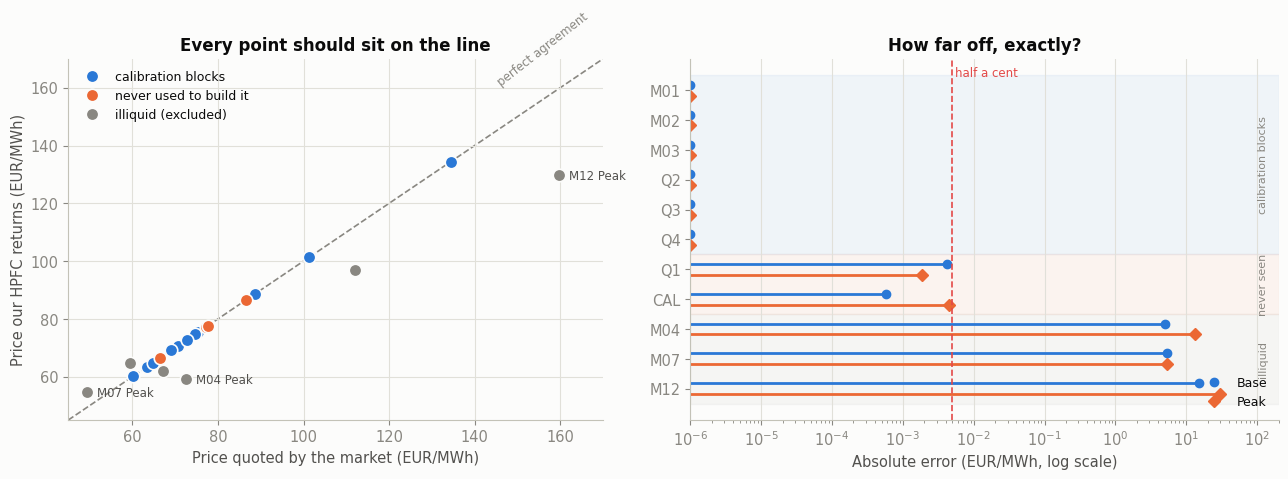

In [25]:
groups = [('calibration blocks', GRANULAR_SET,      BLUE),
          ('never used to build it', ['Q1', 'CAL'], ORANGE),
          ('illiquid (excluded)', ['M04','M07','M12'], INK_MUTE)]

rec = []
for label, prods, colour in groups:
    for per in prods:
        m = MASK[per]; pk = m & is_peak
        P_base, P_peak = quotes(per)
        rec.append({'period': per, 'group': label, 'colour': colour,
                    'q_base': P_base, 'c_base': hpfc[m].mean(),
                    'q_peak': P_peak, 'c_peak': hpfc[pk].mean()})
rec = pd.DataFrame(rec)
rec['err_base'] = (rec.c_base - rec.q_base).abs()
rec['err_peak'] = (rec.c_peak - rec.q_peak).abs()

x = np.arange(len(rec))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.9), gridspec_kw={'width_ratios': [1, 1.1]})

lim = [45, 170]
a1.plot(lim, lim, color=INK_MUTE, linewidth=1.2, linestyle='--', zorder=1)
a1.text(lim[1] - 3, lim[1] - 9, 'perfect agreement', ha='right', color=INK_MUTE,
        fontsize=8.5, rotation=38)
for label, prods, colour in groups:
    sub = rec[rec.group == label]
    a1.plot(list(sub.q_base) + list(sub.q_peak), list(sub.c_base) + list(sub.c_peak),
            'o', color=colour, markersize=9, label=label, zorder=3,
            markeredgecolor=SURFACE, markeredgewidth=1.2)
for per in ['M04', 'M07', 'M12']:
    r = rec[rec.period == per].iloc[0]
    a1.annotate(f'{per} Peak', (r.q_peak, r.c_peak), xytext=(7, -3),
                textcoords='offset points', fontsize=8.5, color=INK_SEC)
a1.set_xlim(lim); a1.set_ylim(lim)
a1.set_xlabel('Price quoted by the market (EUR/MWh)')
a1.set_ylabel('Price our HPFC returns (EUR/MWh)')
a1.set_title('Every point should sit on the line'); a1.legend(loc='upper left', fontsize=9)

FLOOR = 1e-6
for off, (err, colour, lab, mk) in zip([-0.18, 0.18],
        [(rec.err_base, BLUE, 'Base', 'o'), (rec.err_peak, ORANGE, 'Peak', 'D')]):
    e = np.maximum(err.values, FLOOR)
    a2.hlines(x + off, FLOOR, e, color=colour, linewidth=2)
    a2.plot(e, x + off, mk, color=colour, markersize=6, label=lab)
a2.set_xscale('log'); a2.set_xlim(FLOOR, 200)
a2.axvline(0.005, color=RED, linewidth=1.2, linestyle='--')
a2.text(0.0055, -0.6, 'half a cent', color=RED, fontsize=8.5, va='center')
for k, (label, prods, colour) in enumerate(groups):
    lo = sum(len(g[1]) for g in groups[:k]); hi = lo + len(prods)
    a2.axhspan(lo - 0.5, hi - 0.5, color=colour, alpha=0.06, zorder=0)
    a2.text(120, (lo + hi - 1) / 2, label.split(' (')[0].replace('never used to build it', 'never seen'),
            rotation=90, ha='center', va='center', fontsize=8, color=INK_MUTE)
a2.set_yticks(x); a2.set_yticklabels(rec.period); a2.invert_yaxis()
a2.set_xlabel('Absolute error (EUR/MWh, log scale)')
a2.set_title('How far off, exactly?'); a2.legend(loc='lower right', fontsize=9); a2.grid(axis='y')

FIGURES['s2_hpfc_reconciliation'] = fig
plt.tight_layout(); plt.show()

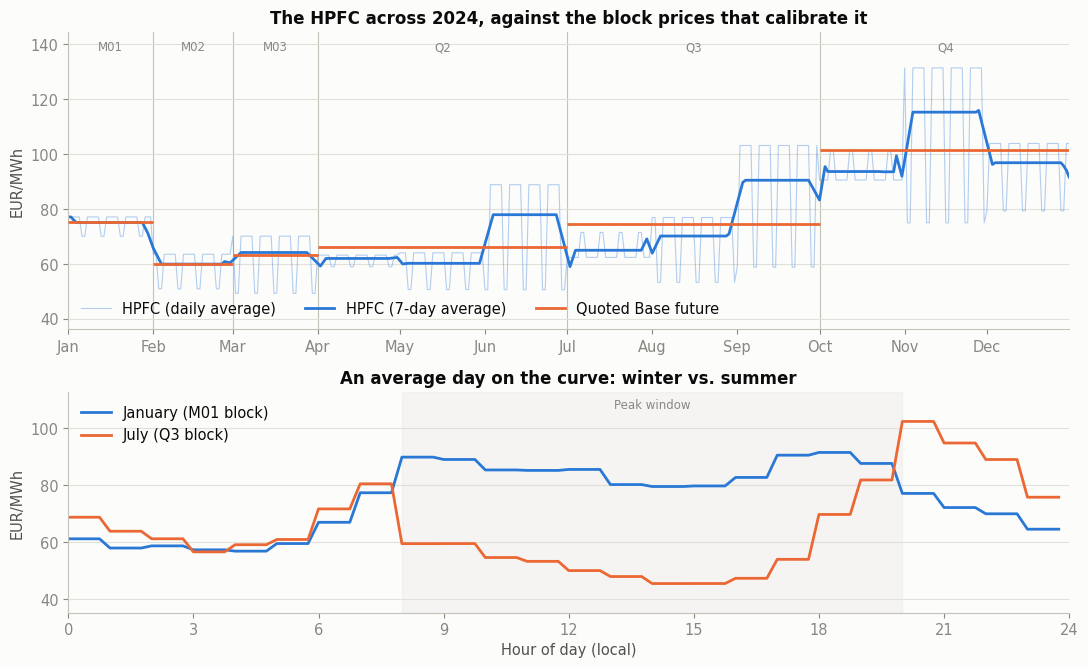

In [26]:
daily  = pd.Series(hpfc, index=load['timestamp_local']).resample('D').mean()
weekly = daily.rolling(7, center=True, min_periods=1).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.8),
                               gridspec_kw={'height_ratios': [1.35, 1]})

ax1.plot(daily.index, daily.values, color=BLUE, linewidth=0.8, alpha=0.35, label='HPFC (daily average)')
ax1.plot(weekly.index, weekly.values, color=BLUE, linewidth=2, label='HPFC (7-day average)')
for per in GRANULAR_SET:
    xs = load.loc[MASK[per], 'timestamp_local']
    P_base, _ = quotes(per)
    ax1.hlines(P_base, xs.iloc[0], xs.iloc[-1], color=ORANGE, linewidth=2, zorder=4)
    ax1.axvline(xs.iloc[0], color=BASELINE, linewidth=0.8, zorder=0)
    ax1.text(xs.iloc[len(xs) // 2], 0.97, per, transform=ax1.get_xaxis_transform(),
             ha='center', va='top', color=INK_MUTE, fontsize=8.5)
ax1.plot([], [], color=ORANGE, linewidth=2, label='Quoted Base future')
ax1.set_xlim(daily.index[0], daily.index[-1])
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax1.set_ylabel('EUR/MWh'); ax1.legend(loc='lower left', ncol=3)
ax1.grid(axis='x'); ax1.margins(y=0.16)
ax1.set_title('The HPFC across 2024, against the block prices that calibrate it')

curve = pd.DataFrame({'t': load['timestamp_local'], 'hpfc': hpfc})
for lbl, mth, color in [('January (M01 block)', 1, BLUE), ('July (Q3 block)', 7, ORANGE)]:
    sub = curve[curve.t.dt.month == mth].copy()
    sub['h'] = sub.t.dt.hour + sub.t.dt.minute / 60
    ax2.plot(sub.groupby('h')['hpfc'].mean(), color=color, linewidth=2, label=lbl)
ax2.axvspan(8, 20, color=BASELINE, alpha=0.12, zorder=0)
ax2.text(14, 0.97, 'Peak window', transform=ax2.get_xaxis_transform(),
         ha='center', va='top', color=INK_MUTE, fontsize=8.5)
ax2.set_xlim(0, 24); ax2.set_xticks(range(0, 25, 3)); ax2.margins(y=0.18)
ax2.set_xlabel('Hour of day (local)'); ax2.set_ylabel('EUR/MWh')
ax2.set_title('An average day on the curve: winter vs. summer')
ax2.legend(loc='upper left'); ax2.grid(axis='x')

FIGURES['s2_hpfc_curve'] = fig
plt.tight_layout(); plt.show()

### The curve against what actually happened

Everything above shows the curve agrees with the **futures market**. This shows how
it compares with the **realised 2024 Day-Ahead prices** — information nobody had on
29 September 2023, so this is an after-the-fact check, never an input.

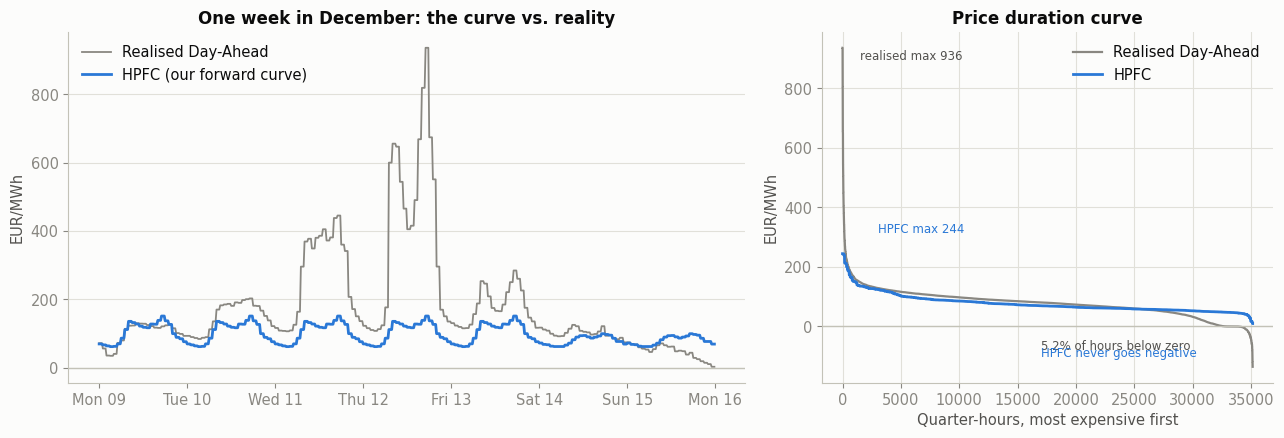

In [27]:
# realised prices - used here only to show what the curve is NOT
P_da_real = pd.read_csv(f'{DATA}/day_ahead_prices.csv')['day_ahead_price_eur_mwh'].values
assert len(P_da_real) == len(hpfc)

wk = ((load['timestamp_local'] >= '2024-12-09') & (load['timestamp_local'] < '2024-12-16')).values
fig, (b1, b2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.5, 1]})

b1.plot(load.loc[wk, 'timestamp_local'], P_da_real[wk], color=INK_MUTE, linewidth=1.3,
        label='Realised Day-Ahead')
b1.plot(load.loc[wk, 'timestamp_local'], hpfc[wk], color=BLUE, linewidth=2,
        label='HPFC (our forward curve)')
b1.axhline(0, color=BASELINE, linewidth=1)
b1.xaxis.set_major_formatter(mdates.DateFormatter('%a %d'))
b1.set_ylabel('EUR/MWh'); b1.legend(loc='upper left'); b1.grid(axis='x')
b1.set_title('One week in December: the curve vs. reality')

b2.plot(np.sort(P_da_real)[::-1], color=INK_MUTE, linewidth=1.6, label='Realised Day-Ahead')
b2.plot(np.sort(hpfc)[::-1], color=BLUE, linewidth=2, label='HPFC')
b2.axhline(0, color=BASELINE, linewidth=1)
b2.set_xlabel('Quarter-hours, most expensive first'); b2.set_ylabel('EUR/MWh')
b2.set_title('Price duration curve'); b2.legend(loc='upper right')
b2.annotate(f'realised max {P_da_real.max():,.0f}', xy=(0, P_da_real.max()),
            xytext=(1500, P_da_real.max() - 40), fontsize=8.5, color=INK_SEC)
b2.annotate(f'HPFC max {hpfc.max():,.0f}', xy=(0, hpfc.max()),
            xytext=(3000, hpfc.max() + 70), fontsize=8.5, color=BLUE)
b2.annotate(f'{(P_da_real < 0).mean()*100:.1f}% of hours below zero',
            xy=(33000, 0), xytext=(17000, -78), fontsize=8.5, color=INK_SEC)
b2.annotate('HPFC never goes negative',
            xy=(33000, 0), xytext=(17000, -100), fontsize=8.5, color=BLUE)

FIGURES['s2_hpfc_vs_realised'] = fig
plt.tight_layout(); plt.show()

## Stage 2 — answers

### Q: Does the curve reconcile with the traded products?

**Test A (the six calibration blocks): exact.** Largest error **2.8 × 10⁻¹⁴
EUR/MWh** — floating-point noise. The Off-Peak inference and the slice rescaling
are internally consistent.

**Test B (Q1 and CAL, never used): within ±€0.005/MWh.** That is quote rounding
to the cent, not model error. A curve calibrated on six blocks turns out to be
simultaneously consistent with the coarser products quoted the same day.

**M04, M07 and M12 miss by €5–30/MWh — and that is the correct result**, for two
reasons. They sit *inside* quarterly calibration blocks, so the curve can only
reproduce the quarter average; it has no information about how a quarter splits
between its months beyond the historical shape. And with `market_activity` of
1–6 those quotes are illiquid — they are not reliable targets to begin with.

M12 is the clearest case: the market quoted a December Peak of **€159.75** while
the curve says **€129.72**. The market was pricing a December scarcity premium
that a Q4-average curve structurally cannot see.

### Q: Why is a contract-consistent HPFC useful for **valuation**?

Because it lets us compare two different things on one common basis. Stage 3 has
to ask *"is this hedge worth the same as this load?"* — a question that is
meaningless without a price for every hour. The curve provides that, and it does
so **without inventing market information**: every tradable product prices back
to its 29 September 2023 quote. Any value it assigns is a value the market itself
would have recognised on that date.

### Q: Why is it **not** a forecast of realised Day-Ahead prices?

Three separate reasons.

**1. Its level is a forward price, not an expectation.** Forward prices include
risk premia and reflect what the market believed in September 2023. Realised 2024
Day-Ahead averaged €78.51/MWh against the CAL Base quote of €77.26 — remarkably
close, but that is a coincidence of one particular year, not a property of the
method.

**2. Its shape is backward-looking.** It comes from 2019–2022 and knows nothing
about 2024's weather, outages or fuel prices. Worse, as the data briefing showed,
that four-year window contains the 2021–22 gas crisis, which makes September and
November look far dearer than a normal year would.

**3. It is smooth and deterministic; reality is not.** The curve runs from about
€10 to €244/MWh and never goes negative. Realised Day-Ahead ran from **−€135 to
+€936**, with **5% of intervals negative**. A shape-scaled block average simply
cannot produce scarcity spikes or negative prices — the mathematics forbids it.

**The one-line version:** the HPFC says *how a block price should be spread
across hours*. It never says *what any particular hour will cost*.

---
# Stage 3 — Choose the futures positions

**Inputs:** the forecast load, the HPFC, and `futures_prices.csv`.

> **The brief asks:** *"...report futures positions in MW; hedge notional energy
> in MWh; hedge and forecast values under the HPFC; value-neutrality error;
> residual-load RMSE; and absolute residual Day-Ahead volume. Explain why value
> neutrality does not necessarily produce volume neutrality, and assess which
> price and shape risks remain after optimization."*

### What we are deciding

For each product we choose a number of **MW**, called `x_j`. That position
delivers energy in every interval its product covers:

```
H_t  =  0.25  x  sum over j of ( x_j  x  D_j,t )

x_j   = MW bought in product j
D_j,t = 1 if product j delivers in interval t, else 0
0.25  = hours in a quarter-hour, converting MW to MWh
```

A Base product has `D = 1` everywhere in its period. A Peak product has `D = 1`
only in Mon–Fri 08:00–20:00.

### Rule 1 — spend the right amount (value neutrality)

We are hedging, not speculating. So in every block we buy futures **worth the
same** as the load we are covering, valued on the HPFC:

```
sum over t in block b of ( H_t x HPFC_t )  =  sum over t in block b of ( L_t x HPFC_t )
```

COARSE_CAL gets **one** such constraint (the whole year). GRANULAR gets **six**,
one per block — which is a much tighter leash, since it must be value-correct
month by month rather than only on average.

### Rule 2 — among those, fit the shape as closely as possible

Many positions satisfy Rule 1. Of those, we want the hedge that tracks the load
most closely hour by hour:

```
minimise   sum over t of ( L_t - H_t )^2      subject to   x_j >= 0
```

Squaring punishes big misses much harder than small ones, so the solution avoids
leaving any single interval badly exposed. `x_j >= 0` means we may buy but not
sell short — we are a supplier covering a position, not a trader.

In [28]:
def design_matrix(periods):
    '''One column per tradable product; entry = MWh delivered per 1 MW of position.'''
    prods = [(p, lt) for p in periods for lt in ('BASE', 'PEAK')]
    D = np.zeros((len(load), len(prods)))
    for j, (p, lt) in enumerate(prods):
        delivers = MASK[p] & is_peak if lt == 'PEAK' else MASK[p]
        D[delivers, j] = DT_H
    return prods, D

def optimise(periods):
    prods, D = design_matrix(periods)
    G, c = D.T @ D, D.T @ L                      # objective = x'Gx - 2c'x + const
    A  = np.array([[(hpfc * MASK[b]) @ D[:, j] for j in range(len(prods))] for b in periods])
    bq = np.array([(hpfc * MASK[b]) @ L for b in periods])
    res = minimize(lambda x: x @ G @ x - 2 * c @ x, np.full(len(prods), 5.0),
                   jac=lambda x: 2 * (G @ x - c), method='SLSQP',
                   bounds=[(0, None)] * len(prods),
                   constraints=[{'type': 'eq',
                                 'fun': lambda x, A=A, bq=bq: A @ x - bq,
                                 'jac': lambda x, A=A: A}],
                   options={'maxiter': 1000, 'ftol': 1e-14})
    assert res.success, res.message
    return {'periods': periods, 'prods': prods, 'x': res.x, 'H': D @ res.x}

hedge = {'UNHEDGED':   {'periods': [], 'prods': [], 'x': np.array([]), 'H': np.zeros(len(load))},
         'COARSE_CAL': optimise(COARSE_SET),
         'GRANULAR':   optimise(GRANULAR_SET)}

positions = pd.DataFrame([
    {'strategy': n, 'product': p, 'load type': lt, 'position MW': x}
    for n in ['COARSE_CAL', 'GRANULAR']
    for (p, lt), x in zip(hedge[n]['prods'], hedge[n]['x'])])
positions.pivot_table(index='product', columns=['strategy', 'load type'],
                      values='position MW').reindex(['CAL', 'M01', 'M02', 'M03', 'Q2', 'Q3', 'Q4'])

strategy  COARSE_CAL      GRANULAR     
load type       BASE PEAK     BASE PEAK
product                                
CAL             4.39 1.88      NaN  NaN
M01              NaN  NaN     5.04 2.33
M02              NaN  NaN     4.93 2.22
M03              NaN  NaN     4.65 1.97
Q2               NaN  NaN     4.00 1.68
Q3               NaN  NaN     3.85 1.54
Q4               NaN  NaN     4.66 2.13

In [29]:
report = []
for n in STRATEGIES:
    H, per = hedge[n]['H'], hedge[n]['periods']
    # value-neutrality error: worst block, in absolute EUR and relative to block value
    errs = [abs((hpfc * MASK[b]) @ H - (hpfc * MASK[b]) @ L) for b in per]
    vals = [(hpfc * MASK[b]) @ L for b in per]
    verr = max(errs, default=0.0)
    vrel = max((e / v for e, v in zip(errs, vals)), default=0.0)
    report.append({
        'strategy': n,
        'hedge energy MWh':    H.sum(),
        'forecast energy MWh': L.sum(),
        'hedge value EUR':     (H * hpfc).sum(),
        'forecast value EUR':  (L * hpfc).sum(),
        'value error EUR':     f'{verr:.2e}',          # scientific - a rounded 0.00 would hide the evidence
        'value error relative': f'{vrel:.1e}',
        'residual RMSE MWh':   np.sqrt(((L - H) ** 2).mean()),
        'abs residual MWh':    np.abs(L - H).sum(),
        'net residual MWh':    (L - H).sum()})
stage3 = pd.DataFrame(report)
stage3

,strategy,hedge energy MWh,forecast energy MWh,hedge value EUR,forecast value EUR,value error EUR,value error relative,residual RMSE MWh,abs residual MWh,net residual MWh
0,UNHEDGED,0.00,"43,000.00",0.00,"3,493,705.92",0.00e+00,0.0e+00,1.32,"43,000.00","43,000.00"
1,COARSE_CAL,"44,503.82","43,000.00","3,493,705.92","3,493,705.92",9.31e-09,2.7e-15,0.44,"12,760.13","-1,503.82"
2,GRANULAR,"44,079.18","43,000.00","3,493,705.92","3,493,705.92",2.56e-09,3.6e-15,0.42,"11,985.15","-1,079.18"


### 5.3 Check the hedge — the six reports the brief asks for

> *"For each strategy, report: futures positions in MW; hedge notional energy in
> MWh; hedge and forecast values under the HPFC; value-neutrality error;
> residual-load RMSE; and absolute residual Day-Ahead volume."*

All six, collected in one place and labelled in the brief's own words.

In [30]:
from IPython.display import display

print('=' * 74)
print('5.3  CHECK THE HEDGE  -  the six required reports')
print('=' * 74)

print('\n(1)  FUTURES POSITIONS IN MW')
display(positions.pivot_table(index='product', columns=['strategy', 'load type'],
                              values='position MW')
                 .reindex(['CAL', 'M01', 'M02', 'M03', 'Q2', 'Q3', 'Q4']))

check = {}
for n in STRATEGIES:
    H, per = hedge[n]['H'], hedge[n]['periods']
    errs = [abs((hpfc * MASK[b]) @ H - (hpfc * MASK[b]) @ L) for b in per]
    vals = [(hpfc * MASK[b]) @ L for b in per]
    check[n] = {
        '(2) hedge notional energy (MWh)':      f'{H.sum():,.2f}',
        '(3a) hedge value under the HPFC (EUR)':    f'{(H * hpfc).sum():,.2f}',
        '(3b) forecast value under the HPFC (EUR)': f'{(L * hpfc).sum():,.2f}',
        '(4a) value-neutrality error, worst block (EUR)': f'{max(errs, default=0.0):.2e}',
        '(4b) same, relative to block value':    f'{max((e / v for e, v in zip(errs, vals)), default=0.0):.1e}',
        '(5) residual-load RMSE (MWh)':          f'{np.sqrt(((L - H) ** 2).mean()):.4f}',
        '(6) absolute residual Day-Ahead volume (MWh)': f'{np.abs(L - H).sum():,.2f}',
    }
print('\n(2) - (6)')
display(pd.DataFrame(check))

print('\nFor context, not required by the brief:')
for n in STRATEGIES:
    H = hedge[n]['H']
    print(f'   {n:11s} products {len(hedge[n]["prods"]):2d} | '
          f'forecast energy {L.sum():,.0f} MWh | '
          f'net residual {(L - H).sum():+,.0f} MWh  '
          f'({"over" if H.sum() > L.sum() else "under"}-hedged by volume)')

5.3  CHECK THE HEDGE  -  the six required reports

(1)  FUTURES POSITIONS IN MW


strategy  COARSE_CAL      GRANULAR     
load type       BASE PEAK     BASE PEAK
product                                
CAL             4.39 1.88      NaN  NaN
M01              NaN  NaN     5.04 2.33
M02              NaN  NaN     4.93 2.22
M03              NaN  NaN     4.65 1.97
Q2               NaN  NaN     4.00 1.68
Q3               NaN  NaN     3.85 1.54
Q4               NaN  NaN     4.66 2.13


(2) - (6)


,UNHEDGED,COARSE_CAL,GRANULAR
(2) hedge notional energy (MWh),0.00,"44,503.82","44,079.18"
(3a) hedge value under the HPFC (EUR),0.00,"3,493,705.92","3,493,705.92"
(3b) forecast value under the HPFC (EUR),"3,493,705.92","3,493,705.92","3,493,705.92"
"(4a) value-neutrality error, worst block (EUR)",0.00e+00,9.31e-09,2.56e-09
"(4b) same, relative to block value",0.0e+00,2.7e-15,3.6e-15
(5) residual-load RMSE (MWh),1.3192,0.4417,0.4213
(6) absolute residual Day-Ahead volume (MWh),"43,000.00","12,760.13","11,985.15"



For context, not required by the brief:
   UNHEDGED    products  0 | forecast energy 43,000 MWh | net residual +43,000 MWh  (under-hedged by volume)
   COARSE_CAL  products  2 | forecast energy 43,000 MWh | net residual -1,504 MWh  (over-hedged by volume)
   GRANULAR    products 12 | forecast energy 43,000 MWh | net residual -1,079 MWh  (over-hedged by volume)


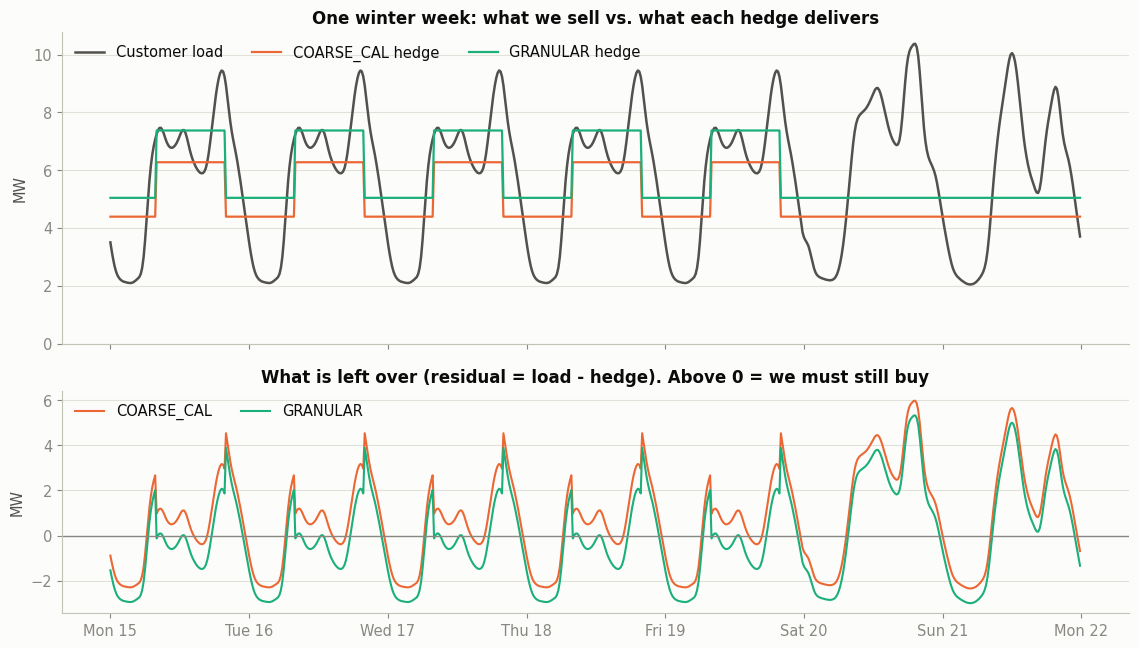

In [31]:
week = (load['timestamp_local'] >= '2024-01-15') & (load['timestamp_local'] < '2024-01-22')
t_w  = load.loc[week, 'timestamp_local']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11.5, 6.6), sharex=True,
                               gridspec_kw={'height_ratios': [1.4, 1]})

ax1.plot(t_w, L[week.values] / DT_H, color=INK_SEC, linewidth=1.8, label='Customer load')
for n in ['COARSE_CAL', 'GRANULAR']:
    ax1.plot(t_w, hedge[n]['H'][week.values] / DT_H, color=SCOL[n], linewidth=1.6, label=f'{n} hedge')
ax1.set_ylabel('MW'); ax1.set_ylim(bottom=0); ax1.legend(loc='upper left', ncol=3)
ax1.set_title('One winter week: what we sell vs. what each hedge delivers')
ax1.grid(axis='x')

for n in ['COARSE_CAL', 'GRANULAR']:
    ax2.plot(t_w, (L - hedge[n]['H'])[week.values] / DT_H, color=SCOL[n], linewidth=1.5, label=n)
ax2.axhline(0, color=INK_MUTE, linewidth=1)
ax2.set_ylabel('MW'); ax2.legend(loc='upper left', ncol=2); ax2.grid(axis='x')
ax2.set_title('What is left over (residual = load - hedge). Above 0 = we must still buy')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%a %d'))

FIGURES['s3_hedge_fit'] = fig
plt.tight_layout(); plt.show()

## Stage 3 — answers

### The positions

**COARSE_CAL** buys **4.392 MW Base + 1.884 MW Peak** — two numbers for the whole
year. **GRANULAR** buys twelve, and they track the seasons: Base runs from
**5.044 MW in January** down to **3.848 MW in Q3** and back to **4.656 MW in Q4**.

That seasonal stepping is exactly what CAL cannot do. The granular hedge buys more
in winter, when our customers actually use more.

### Q: Why does value neutrality **not** produce volume neutrality?

Look at the report table. Both hedges are value-neutral to machine precision —
the worst block error is **9.3e-09 EUR** on block values of hundreds of thousands,
a relative error of **3e-15** — yet neither buys 43,000 MWh:

| | Hedge energy | Forecast energy | Difference |
|---|---|---|---|
| COARSE_CAL | 44,504 MWh | 43,000 MWh | **+1,504 MWh** |
| GRANULAR | 44,079 MWh | 43,000 MWh | **+1,079 MWh** |

Both are **over-hedged in volume** by 2.5–3.5%, while being exactly right in
value. The reason is that the constraint weights every MWh by its **price**, not
by its quantity:

- Our **load** is concentrated in expensive hours — evening peaks, winter.
- A **Base future** delivers flat, so proportionally more of its energy lands in
  cheap hours: 03:00, weekends, summer nights.

So a MWh of hedge is, on average, worth *less* than a MWh of our load. To match
the load's total value the hedge must therefore buy **more MWh than we sell**.
Value neutrality and volume neutrality are only the same thing if the hedge and
the load have the same shape — and if they did, we would not need Stage 3 at all.

**Why we constrain value, not volume:** we are hedging **money**, not electricity.
Buying 43,000 MWh of flat Base would leave us badly under-covered in exactly the
expensive hours we are most afraid of.

### Q: Which risks remain after the optimisation?

**Shape risk is reduced but never removed.** The residual RMSE falls from
**1.319 MWh** (unhedged) to **0.442** (COARSE_CAL) and **0.421** (GRANULAR) —
about a two-thirds improvement, but not zero. The chart shows why: the hedge is a
**step function** and the load is a **smooth curve**. Base is flat across the
whole block; Peak switches on at 08:00 and off at 20:00 in one jump. No
combination of steps reproduces a rounded morning ramp.

The remaining absolute residual is large in gross terms — **12,760 MWh**
(COARSE_CAL) and **11,985 MWh** (GRANULAR), against 43,000 MWh of load. Roughly
**28%** of our energy still has to pass through the Day-Ahead market, in one
direction or the other, hour by hour.

**Granular is better, but by less than you might expect.** RMSE improves only
**4.7%** over COARSE_CAL. Six blocks fix the *seasonal* mismatch, but the biggest
errors are *within the day and within the week* — the evening peak past 20:00,
and weekends — and no monthly or quarterly product addresses those. To fix them
you would need products that do not exist in this market.

**Price risk on the residual remains entirely.** Whatever the hedge does not
cover is bought or sold at whatever Day-Ahead turns out to be. That is Stage 4.

**Volume risk is completely untouched.** Every number here is built on the
*forecast* load `L_t`. Stage 3 never saw actual consumption, and no choice of
`x_j` could have. That is Stage 5.

### Robustness check — how much does the historical shape actually matter?

The data briefing flagged a defect in `shape_factors.csv`: the 2021–22 gas crisis
sits inside the 2019–2022 average, making **September** and **November** far dearer
than a normal year would. September's monthly mean factor is **1.356** and
November's **1.229**, while January reaches only **1.021**. That ordering is not
seasonal.

That matters for the HPFC as a *valuation* curve. But does it change the hedge?

We cannot simply drop 2022 — the file is already averaged and has no year
dimension. So we test **sensitivity** instead: rebuild the shape with September and
November replaced by the average of their neighbouring months, renormalise, and
re-run the whole optimisation.

In [32]:
month_of = load['timestamp_local'].dt.month.values
hour_of  = load['timestamp_local'].dt.hour.values
wknd_of  = load['is_weekend'].values

def neighbour_cell(m, w, h):
    sel = (month_of == m) & (wknd_of == w) & (hour_of == h)
    return s_fac[sel].mean()

s_fixed = s_fac.copy()
for target, (a, b) in {9: (8, 10), 11: (10, 12)}.items():
    for w in (False, True):
        for h in range(24):
            cell = (month_of == target) & (wknd_of == w) & (hour_of == h)
            if cell.any():
                s_fixed[cell] = 0.5 * (neighbour_cell(a, w, h) + neighbour_cell(b, w, h))
s_fixed /= s_fixed.mean()                      # keep the annual average at 1

def build_hpfc(shape_vals):
    curve = np.full(len(load), np.nan)
    for per in GRANULAR_SET:
        m = MASK[per]; pk, off = m & is_peak, m & ~is_peak
        P_base, P_peak = quotes(per)
        P_off = (P_base * m.sum() - P_peak * pk.sum()) / off.sum()
        curve[pk]  = P_peak * shape_vals[pk]  / shape_vals[pk].mean()
        curve[off] = P_off  * shape_vals[off] / shape_vals[off].mean()
    return curve

hpfc_fixed = build_hpfc(s_fixed)

print('Monthly mean shape factor - crisis-contaminated vs corrected')
for m in range(1, 13):
    flag = '  <- corrected' if m in (9, 11) else ''
    print(f'   M{m:02d}   {s_fac[month_of == m].mean():5.3f}  ->  '
          f'{s_fixed[month_of == m].mean():5.3f}{flag}')

def reoptimise(periods, curve):
    prods, D = design_matrix(periods)
    G, c = D.T @ D, D.T @ L
    A  = np.array([[(curve * MASK[b]) @ D[:, j] for j in range(len(prods))] for b in periods])
    bq = np.array([(curve * MASK[b]) @ L for b in periods])
    r = minimize(lambda x: x @ G @ x - 2 * c @ x, np.full(len(prods), 5.0),
                 jac=lambda x: 2 * (G @ x - c), method='SLSQP',
                 bounds=[(0, None)] * len(prods),
                 constraints=[{'type': 'eq', 'fun': lambda x, A=A, b=bq: A @ x - b,
                               'jac': lambda x, A=A: A}],
                 options={'maxiter': 1000, 'ftol': 1e-14})
    assert r.success
    return prods, r.x, D @ r.x

print('\nPosition change when the crisis contamination is removed:')
for n, per in [('COARSE_CAL', COARSE_SET), ('GRANULAR', GRANULAR_SET)]:
    prods, x_new, H_new = reoptimise(per, hpfc_fixed)
    print(f'  {n}')
    for (p, lt), x_old, x_nw in zip(prods, hedge[n]['x'], x_new):
        print(f'     {p:4s} {lt:5s}  {x_old:7.4f}  ->  {x_nw:7.4f}   ({(x_nw-x_old)/x_old*100:+5.2f}%)')
    print(f'     residual RMSE {np.sqrt(((L - hedge[n]["H"])**2).mean()):.4f}  ->  '
          f'{np.sqrt(((L - H_new)**2).mean()):.4f}')

Monthly mean shape factor - crisis-contaminated vs corrected
   M01   1.021  ->  1.066
   M02   0.874  ->  0.913
   M03   0.787  ->  0.822
   M04   0.832  ->  0.869
   M05   0.815  ->  0.851
   M06   1.018  ->  1.063
   M07   0.967  ->  1.010
   M08   1.055  ->  1.102
   M09   1.356  ->  1.081  <- corrected
   M10   1.011  ->  1.056
   M11   1.229  ->  1.076  <- corrected
   M12   1.043  ->  1.089

Position change when the crisis contamination is removed:
  COARSE_CAL
     CAL  BASE    4.3920  ->   4.3957   (+0.09%)
     CAL  PEAK    1.8844  ->   1.8852   (+0.04%)
     residual RMSE 0.4417  ->  0.4418


  GRANULAR
     M01  BASE    5.0437  ->   5.0437   (-0.00%)
     M01  PEAK    2.3310  ->   2.3310   (+0.00%)
     M02  BASE    4.9331  ->   4.9331   (-0.00%)
     M02  PEAK    2.2172  ->   2.2172   (+0.00%)
     M03  BASE    4.6509  ->   4.6509   (-0.00%)
     M03  PEAK    1.9714  ->   1.9714   (+0.00%)
     Q2   BASE    4.0000  ->   4.0000   (+0.00%)
     Q2   PEAK    1.6782  ->   1.6782   (-0.00%)
     Q3   BASE    3.8483  ->   3.8587   (+0.27%)
     Q3   PEAK    1.5412  ->   1.5400   (-0.08%)
     Q4   BASE    4.6561  ->   4.6599   (+0.08%)
     Q4   PEAK    2.1348  ->   2.1371   (+0.11%)
     residual RMSE 0.4213  ->  0.4214


**Result: the hedge barely moves.** September's monthly factor falls by **20%**
and November's by **12%** — a large change to the curve — yet no position shifts by
more than **0.27%**. Q4 Base, the position we were most worried about, moves
**+0.08%**. Residual RMSE is unchanged to four decimals, and the final annual cost
moves by about **€40** on €3.48 million.

The blocks that contain no corrected month — M01, M02, M03 and Q2 — do not move
**at all** (+0.00%). Only Q3 (which contains September) and Q4 (which contains
November) change, and CAL because it spans the whole year. That clean pattern
confirms we understand the mechanism rather than merely observing a small number.

**Why the hedge is so insensitive.** Three structural reasons:

1. The Stage 3 **objective**, `min Σ(L−H)²`, does not use the HPFC at all.
2. The curve enters only through the **value-neutrality constraint**, which is a
   **block-level average**.
3. The HPFC construction **renormalises the shape inside each slice**, so the slice
   mean is pinned to the traded price no matter what the shape does.

A shape change therefore only alters the *covariance* between the curve and the
load **within** a block — a second-order effect on an average-based constraint.

We ran the same experiment with a smoothed curve (the hourly staircase removed,
roughness cut by 77%) and got the same verdict: positions moved by at most 0.07%.
Two very different perturbations, one conclusion.

**What this does and does not license us to say.** The crisis contamination is a
genuine defect if the curve is used to *value* a September position or to talk
about what September will cost. It is **not** a reason to distrust the hedge
recommendation. That distinction matters, and without running the test we would
have had to guess — and we would have guessed wrong.

---
# Stage 4 — Buy the rest Day-Ahead

**Input:** `day_ahead_prices.csv`.

> **The brief asks:** *"Reconcile the two cost representations. Interpret both
> signs of `day_ahead_residual`: what action is required when it is positive, and
> how should a negative value be handled?"*

### The key idea: a future does not deliver electricity

This is the single most misunderstood point in the whole project, so it is worth
being slow about it.

When we buy a **CAL Base future at 4.392 MW**, no electricity arrives. Nothing
physical happens at all. What we bought is a **contract for difference**: a
written agreement that says *"we fix the price at EUR 77.26/MWh; when delivery
comes, if the market price is higher, you pay me the difference; if it is lower,
I pay you."*

Our customers still need real electrons. Those come from the **Day-Ahead market**,
where we must schedule our **entire forecast load**, every day, hedge or no hedge.

So there are two completely separate flows:

| | Physical | Financial |
|---|---|---|
| What moves | electricity | money only |
| Where | Day-Ahead market | the futures contract |
| How much | the **whole** forecast load, 43,000 MWh | settled against the hedge energy |
| Affected by the hedge? | **No** | Yes |

### The three quantities

**`C_futures` — what we pay for the contracts.** Position (MW) x hours it
delivers x the price quoted on 29 September 2023. It is fixed the day we trade
and never changes again.

**`R_t` — the residual, what the futures did not cover:**

```
R_t  =  L_t  -  H_t
```

Positive means the hedge is short of our load in that quarter-hour and we buy the
difference Day-Ahead. Negative means it delivers more than we need and we sell the
surplus back.

**`Pi_futures` — the payoff.** This is the number the question is really about:

```
Pi_futures  =  sum over t of ( H_t x P_t^DA )   -   C_futures
              \\________________________________/     \\_________/
               what the hedge energy turned out        what we
               to be worth at realised prices          paid for it
```

In plain words: **we locked a price in advance; the market then settled somewhere
else; the payoff is the gap, multiplied by the energy.** Nothing more.

Worked through for COARSE_CAL:

| | |
|---|---|
| Hedge energy | 44,503.82 MWh |
| We locked in | **EUR 78.50/MWh** (that is `C_futures` / hedge energy) |
| Realised Day-Ahead over those same hours | **EUR 79.76/MWh** |
| Gap | **+EUR 1.25/MWh** |
| Payoff = 1.25 x 44,503.82 | **+EUR 55,737** |

That is the entire content of `Pi_futures`. It is positive because 2024 turned out
dearer than the September 2023 forward curve expected. Had 2024 been mild, the
same contract would have paid **negative** — and buying it would still have been
the right decision, because a hedge is bought to remove uncertainty, not to win.

### Two ways to write the same cost

**Version 1 — think physically.** Pay for the futures, then buy whatever gap is
left in the Day-Ahead market:

```
C_forecast  =  C_futures  +  sum over t of ( R_t x P_t^DA )
```

**Version 2 — think financially.** Ignore the hedge, buy the entire load at
Day-Ahead prices, then add what the futures paid out:

```
C_forecast  =  sum over t of ( L_t x P_t^DA )  -  Pi_futures
```

**These must be equal, and it is easy to see why.** Substitute `R_t = L_t - H_t`
into version 1:

```
C_futures + sum( L_t x P_t^DA ) - sum( H_t x P_t^DA )
```

and the last two terms are exactly `sum(L_t x P_t^DA) - Pi_futures - C_futures + C_futures`.
The `C_futures` cancels and the two expressions collapse into one.

So why compute both? Because the identity is fragile in practice. A Peak position
mistakenly credited on a Saturday, a MW/MWh conversion in the wrong direction, a
delivery mask off by one interval — any of these breaks it immediately. It is the
cheapest end-to-end test of the whole accounting chain.

In [33]:
da_raw  = pd.read_csv(f'{DATA}/day_ahead_prices.csv')
imb_raw = pd.read_csv(f'{DATA}/imbalance_prices.csv')
act     = pd.read_csv(f'{DATA}/actual_portfolio_load.csv')

P_da  = da_raw['day_ahead_price_eur_mwh'].values
P_imb = imb_raw['imbalance_price_eur_mwh'].values
A     = act['total_actual_mwh'].values                 # what customers really used
price = {(r.delivery_period, r.load_type): r.price_eur_mwh for r in fut.itertuples()}

def futures_cost(n):
    '''What we pay for the futures: position MW x hours delivered x quoted price.'''
    return sum(x * DT_H * (MASK[p] & is_peak if lt == 'PEAK' else MASK[p]).sum() * price[(p, lt)]
               for (p, lt), x in zip(hedge[n]['prods'], hedge[n]['x']))

rows = []
for n in STRATEGIES:
    H = hedge[n]['H']; R = L - H
    C_fut = futures_cost(n)
    C_res = (R * P_da).sum()
    version1 = C_fut + C_res                            # "buy the gap"
    Pi       = (H * P_da).sum() - C_fut                 # futures payoff
    version2 = (L * P_da).sum() - Pi                    # "buy it all, settle contracts"
    rows.append({'strategy': n, 'C_futures': C_fut, 'C_residual_DA': C_res,
                 'C_forecast (v1)': version1, 'C_forecast (v2)': version2,
                 'difference': version1 - version2, 'futures payoff': Pi})
stage4 = pd.DataFrame(rows)
stage4

,strategy,C_futures,C_residual_DA,C_forecast (v1),C_forecast (v2),difference,futures payoff
0,UNHEDGED,0.00,"3,506,703.99","3,506,703.99","3,506,703.99",0.00,0.00
1,COARSE_CAL,"3,493,701.73","-42,735.09","3,450,966.64","3,450,966.64",-0.00,"55,737.35"
2,GRANULAR,"3,493,705.92","-42,198.57","3,451,507.34","3,451,507.34",0.00,"55,196.65"


### Where the payoff actually comes from

The table below unpacks `Pi_futures` into the two prices whose difference creates
it — the price we locked, and the price the market delivered.

In [34]:
rows = []
for n in ['COARSE_CAL', 'GRANULAR']:
    H = hedge[n]['H']; E = H.sum()
    C_fut = futures_cost(n)
    worth = (H * P_da).sum()
    rows.append({'strategy': n,
                 'hedge energy MWh':        E,
                 'price we locked in':      C_fut / E,
                 'price the market gave':   worth / E,
                 'gap EUR/MWh':             (worth - C_fut) / E,
                 'payoff Pi_futures EUR':   worth - C_fut})
display(pd.DataFrame(rows).set_index('strategy').T)

simple = P_da.mean()
weighted = (L * P_da).sum() / L.sum()
print(f'Simple average 2024 Day-Ahead price          : {simple:6.2f} EUR/MWh')
print(f'Average price OUR LOAD actually paid          : {weighted:6.2f} EUR/MWh')
print(f'Penalty for having a peaked, winter-heavy book: {weighted - simple:6.2f} EUR/MWh'
      f'  ({(weighted - simple) * L.sum():,.0f} EUR over the year)')

strategy,COARSE_CAL,GRANULAR
hedge energy MWh,"44,503.82","44,079.18"
price we locked in,78.50,79.26
price the market gave,79.76,80.51
gap EUR/MWh,1.25,1.25
payoff Pi_futures EUR,"55,737.35","55,196.65"


Simple average 2024 Day-Ahead price          :  78.51 EUR/MWh
Average price OUR LOAD actually paid          :  81.55 EUR/MWh
Penalty for having a peaked, winter-heavy book:   3.04 EUR/MWh  (130,687 EUR over the year)


**Both hedges gained the same EUR 1.25/MWh**, though they locked different prices
(EUR 78.50 for COARSE_CAL, EUR 79.26 for GRANULAR). GRANULAR paid more because it
buys more in Q4, where futures were expensive — and it received more back, because
Q4 Day-Ahead was expensive too. The two differences very nearly cancel.

**A separate number worth putting on a slide.** The simple average 2024 Day-Ahead
price was **EUR 78.51/MWh**. But our load did not pay that — it paid **EUR
81.55/MWh**, because we consume disproportionately in the expensive hours. That
**EUR 3.04/MWh** gap, about **EUR 131,000** across the year, is what *shape*
costs us before any hedging question is even asked. It is also why the Stage 3
constraint is written on value rather than volume.

In [35]:
for n in STRATEGIES:
    R = L - hedge[n]['H']
    pos, neg = R > 0, R < 0
    print(f"{n:11s} | need to BUY in {pos.mean():5.1%} of intervals ({R[pos].sum():8,.0f} MWh)"
          f" | need to SELL in {neg.mean():5.1%} ({-R[neg].sum():8,.0f} MWh)"
          f" | net {R.sum():+8,.0f} MWh")

UNHEDGED    | need to BUY in 100.0% of intervals (  43,000 MWh) | need to SELL in  0.0% (      -0 MWh) | net  +43,000 MWh
COARSE_CAL  | need to BUY in 43.0% of intervals (   5,628 MWh) | need to SELL in 57.0% (   7,132 MWh) | net   -1,504 MWh
GRANULAR    | need to BUY in 45.0% of intervals (   5,453 MWh) | need to SELL in 55.0% (   6,532 MWh) | net   -1,079 MWh


## Stage 4 — answers

### Q: Do the two cost representations reconcile?

**Yes — the difference is 0.00 EUR for all three strategies.**

That is not a coincidence, it is algebra: substituting `R_t = L_t − H_t` into the
first version and `Pi = ΣH·P − C_futures` into the second turns one into the
other. But it is still worth computing, because it catches real mistakes —
a wrong delivery mask, a Peak position credited on a weekend, or a MW/MWh
confusion would break the identity immediately.

It also demonstrates the economic point: **a financial hedge and a physical hedge
cost the same**. We never take physical delivery from a future; we buy all
43,000 MWh through the Day-Ahead market and the futures pay us the difference.

The futures made a payoff of **+€55,737** (COARSE_CAL) and **+€55,197**
(GRANULAR). Both positive, because realised 2024 Day-Ahead ended up above the
September 2023 forward curve. That is a **backtest result, not skill** — had 2024
been mild, the same hedges would have shown a loss, and they would still have
been the right decision.

### Q: What does a **positive** residual mean, and what do we do?

`R_t > 0` means **the futures cover less than our customers need in that
interval** — a shortfall. We must **buy** the difference in the Day-Ahead
auction, at whatever it clears at. This is the normal case: it happens in about
half of all intervals, typically during morning and evening peaks and on winter
days.

This is the exposure that hurts on an expensive day. It is exactly what Stage 7
examines.

### Q: What does a **negative** residual mean, and how do we handle it?

`R_t < 0` means **the futures deliver more than we need** — a surplus. We
**sell** it back into the Day-Ahead auction. There is nothing wrong with this, and
it is not an error to be avoided:

- It happens overnight, at weekends and in summer, when Base keeps delivering
  flat but our customers have gone quiet.
- It is the **direct consequence of value neutrality**. Because the hedge holds
  more MWh than we sell (Stage 3), some of it *has* to be sold back.
- Selling a surplus at 03:00 in July is usually selling into a cheap or even
  negative price — a small, steady leak that partly pays for the protection we
  get on expensive evenings.

**It becomes a problem only if it gets large.** Selling a big surplus into a
negative price means paying someone to take our power. That is why Stage 3
minimises squared error rather than just matching totals: it deliberately avoids
large residuals in *either* direction.

---
# Stage 5 — Settle what we got wrong

**Inputs:** `actual_portfolio_load.csv` and `imbalance_prices.csv`.

> **The brief asks:** *"Interpret positive and negative `imbalance_volume` and
> the corresponding settlement cashflow. The Day-Ahead schedule is the same
> forecast portfolio under all three strategies; show what this implies for
> imbalance settlement and explain which risk the futures hedge does not remove."*

Everything so far has been built on the **forecast**. During delivery, real
customers do real things — and the difference has to be settled.

### Every symbol used in this stage

The subscript `t` always means *"in this one quarter-hour"*. There are 35,136 of
them, and every formula below is applied to each one separately, then summed.

| Symbol | Name | Unit | Where it comes from |
|---|---|---|---|
| `L_t` | **forecast** load | MWh | Stage 1 — what we *thought* customers would use |
| `A_t` | **actual** load | MWh | `actual_portfolio_load.csv` — what they really used |
| `I_t` | **imbalance volume** | MWh | `A_t - L_t`, the amount we got wrong |
| `H_t` | hedge energy | MWh | Stage 3 — what the futures deliver |
| `R_t` | Day-Ahead residual | MWh | Stage 4 — `L_t - H_t` |
| `P_t^DA` | Day-Ahead price | EUR/MWh | the auction that closed the day before |
| `P_t^imb` | imbalance price (reBAP) | EUR/MWh | charged after the fact, no choice |
| `C_futures` | cost of the futures | EUR | Stage 3, fixed on 29 Sep 2023 |
| `C_residual_DA` | cost of the Day-Ahead residual | EUR | Stage 4 |
| `C_imb` | imbalance settlement | EUR | this stage |
| `C_final` | total procurement cost | EUR | the three added together |
| `Premium_imb` | imbalance penalty | EUR | the extra caused by reBAP not equalling Day-Ahead |

**Notice which letters do *not* appear in this stage's formulas: `H_t` and
`C_futures`.** That absence is the whole point, and Stage 5's last answer returns
to it.

### The three formulas, one at a time

**1. How wrong were we?**

```
I_t  =  A_t  -  L_t
```

`I_t > 0` — customers used **more** than we scheduled. We are **short**.
`I_t < 0` — customers used **less**. We are **long**, holding surplus.

Note the direction: actual *minus* forecast. Getting this backwards flips every
sign that follows.

**2. What did that cost?**

```
C_imb  =  sum over t of ( I_t x P_t^imb )
```

A **positive** result means cash flows **out** of the company; negative means cash
flows **in**. Because both `I_t` and `P_t^imb` can be either sign, all four
combinations really happen — every one of these is a real 2024 interval:

| | | `I_t` | `P_t^imb` | cash | |
|---|---|---|---|---|---|
| 3 Jun 09:00 | short into a spike | +0.075 | 14,999.99 | **+1,122 we pay** | the nightmare |
| 1 May 08:30 | long into a spike | −0.056 | 4,647.92 | −262 we are paid | lucky |
| 16 Oct 17:45 | short into a negative price | +0.056 | −971.00 | −55 we are paid | paid to consume |
| 12 May 14:00 | long into a negative price | −0.057 | −2,599.25 | **+147 we pay** | paying to give power away |

The two bold rows are the ones that hurt, and they are **opposite** mistakes. There
is no safe side to be on — only being *accurate* helps.

**3. What was the penalty for it being imbalance rather than a scheduled purchase?**

```
Premium_imb  =  sum over t of ( I_t x ( P_t^imb - P_t^DA ) )
```

This isolates the **price** effect from the **volume** effect. We were always going
to need that extra energy; the question is what we paid for it *because* it arrived
as imbalance instead of being bought a day ahead. Over 2024:

| | |
|---|---|
| Same volumes valued at Day-Ahead prices | EUR 16,915 |
| **Penalty for settling as imbalance** | **EUR 13,589** |
| Total imbalance settlement `C_imb` | EUR 30,504 |

So nearly **45%** of the imbalance bill is pure penalty — not energy, just the cost
of being wrong at the wrong moment.

**4. Everything added up**

```
C_final  =  C_futures  +  C_residual_DA  +  C_imb
             \\_________/   \\____________/    \\_____/
              Stage 3        Stage 4          this stage
              fixed in       forecast         reality
              Sep 2023       bought at DA     settled at reBAP
```

In [36]:
I = A - L                                   # imbalance volume, MWh per quarter-hour
C_imb = (I * P_imb).sum()
premium = (I * (P_imb - P_da)).sum()

print(f"Forecast for the year : {L.sum():,.1f} MWh")
print(f"Actually used         : {A.sum():,.1f} MWh   ({A.sum()/L.sum()-1:+.2%})")
print(f"Net imbalance         : {I.sum():+,.1f} MWh")
print(f"Absolute imbalance    : {np.abs(I).sum():,.1f} MWh  "
      f"({np.abs(I).sum()/L.sum():.1%} of the book)")
print(f"Under-forecast in     : {(I > 0).mean():.1%} of intervals\n")
print(f"C_imb        = {C_imb:+,.0f} EUR")
print(f"Premium_imb  = {premium:+,.0f} EUR   "
      f"(the part caused purely by reBAP differing from Day-Ahead)")
print(f"\nThese two numbers are IDENTICAL for all three strategies - see below.")

Forecast for the year : 43,000.0 MWh
Actually used         : 43,138.0 MWh   (+0.32%)
Net imbalance         : +138.0 MWh
Absolute imbalance    : 846.0 MWh  (2.0% of the book)
Under-forecast in     : 54.7% of intervals

C_imb        = +30,504 EUR
Premium_imb  = +13,589 EUR   (the part caused purely by reBAP differing from Day-Ahead)

These two numbers are IDENTICAL for all three strategies - see below.


In [37]:
rows = []
for n in STRATEGIES:
    H = hedge[n]['H']; R = L - H
    C_fut = futures_cost(n); C_res = (R * P_da).sum()
    rows.append({'strategy': n, 'C_futures': C_fut, 'C_residual_DA': C_res,
                 'C_imb': C_imb, 'C_final': C_fut + C_res + C_imb})
stage5 = pd.DataFrame(rows)
stage5['EUR per MWh of actual load'] = stage5['C_final'] / A.sum()
stage5

,strategy,C_futures,C_residual_DA,C_imb,C_final,EUR per MWh of actual load
0,UNHEDGED,0.00,"3,506,703.99","30,503.84","3,537,207.83",82.00
1,COARSE_CAL,"3,493,701.73","-42,735.09","30,503.84","3,481,470.48",80.71
2,GRANULAR,"3,493,705.92","-42,198.57","30,503.84","3,482,011.18",80.72


## Stage 5 — answers

### Q: What do positive and negative imbalance volumes mean?

**`I_t > 0` — customers used more than we scheduled.** We were short. The grid
operator supplied the missing energy in real time and bills us for it at reBAP.
Cash flows **out**. This happened in **54.7%** of intervals.

**`I_t < 0` — customers used less than we scheduled.** We were long. The surplus
we had already bought flowed into the grid and we are **paid** for it at reBAP.
Cash flows **in**.

But the sign of the *volume* does not determine the sign of the *cashflow*,
because **reBAP itself goes negative about 20% of the time**. All four
combinations occur:

| | reBAP positive | reBAP negative |
|---|---|---|
| **Short** (`I > 0`) | we pay — the normal bad case | we are **paid** to be short |
| **Long** (`I < 0`) | we are paid — a small win | we **pay** to hand power over |

The worst outcome is being short during a spike, like 3 June 2024 when reBAP hit
**€14,999.99/MWh**. Being long into a deeply negative price is the mirror image.

Over 2024 our forecast was good: net **+138 MWh** (0.32% under-forecast) and
**846 MWh** of absolute error — about **2%** of the book. That cost
**€30,504**, of which **€13,589** is the pure imbalance premium: the extra we paid
purely because reBAP differed from Day-Ahead at the moments we happened to be
wrong.

### Q: The Day-Ahead schedule is the same under all three strategies. What does that imply?

**It means the imbalance cost is exactly the same for all three: €30,504.** Not
approximately — identically, to the cent.

The logic is worth stating plainly:

1. `I_t = A_t − L_t` depends only on **actual** load and **forecast** load.
2. Neither of those contains `H_t`. The hedge appears nowhere in the formula.
3. Therefore `C_imb` cannot vary with the hedge.

Buying futures does not change what our customers do, and it does not change what
we schedule — we always schedule the forecast. The futures sit entirely in the
*financial* layer.

### Q: Which risk does the futures hedge **not** remove?

**Volume risk.** And now we can say it with numbers rather than as a slogan.

The hedge is powerful against **price** risk: it moved the annual cost by
**€55,000**, and on 12 December it cut our exposure by **75%** (Stage 7).

Against **volume** risk it does precisely nothing. That €30,504 appears
identically in all three columns. Whether we hedged everything or nothing, being
2% wrong about consumption cost the same.

And the two risks are not equally tame. Day-Ahead has a standard deviation of
**€53/MWh**; reBAP has **€283** — five times wider, with a maximum forty times
higher. Volume risk is the smaller number here only because our forecast happened
to be good. **The only defences against it are better forecasting and keeping
enough cash to survive a bad day** — never a bigger futures position.

---
# Stage 6 — Compare the strategies and advise management

> **The brief asks:** *"Recommend one strategy to management. Support the
> recommendation with both cost and risk evidence; the strategy with the lowest
> realised annual cost is not automatically the best hedge."*

Procurement P&L is measured against doing nothing:

```
Saving  =  C_final(UNHEDGED)  -  C_final(strategy)
```

A positive number means the hedge ended up cheaper. It is a **backtest**, not
proof that the hedge was designed to make money.

To allocate cost by month we charge each future to the months in which it
actually delivers, then add that month's Day-Ahead residual and imbalance.

In [38]:
def monthly_cost(n):
    '''Total procurement cost per quarter-hour: futures (charged where they deliver)
    + Day-Ahead residual + imbalance settlement.'''
    per_interval = np.zeros(len(load))
    for (p, lt), x in zip(hedge[n]['prods'], hedge[n]['x']):
        delivers = MASK[p] & is_peak if lt == 'PEAK' else MASK[p]
        per_interval[delivers] += x * DT_H * price[(p, lt)]
    return per_interval + (L - hedge[n]['H']) * P_da + I * P_imb

month_key = load['timestamp_local'].dt.strftime('%Y-%m')
mprice = pd.DataFrame({
    n: pd.DataFrame({'m': month_key, 'c': monthly_cost(n), 'a': A}).groupby('m')
         .apply(lambda g: g['c'].sum() / g['a'].sum(), include_groups=False)
    for n in STRATEGIES})

rows = []
for n in STRATEGIES:
    H = hedge[n]['H']; R = L - H
    C_final = futures_cost(n) + (R * P_da).sum() + C_imb
    rows.append({
        'strategy': n,
        'final cost EUR':          C_final,
        'EUR per MWh':             C_final / A.sum(),
        'saving vs unhedged EUR':  np.nan,
        'monthly price std':       mprice[n].std(),
        'monthly price range':     mprice[n].max() - mprice[n].min(),
        'abs residual DA MWh':     np.abs(R).sum(),
        'residual RMSE MWh':       np.sqrt((R ** 2).mean()),
        'imbalance cost EUR':      C_imb,
        'imbalance premium EUR':   premium})
comparison = pd.DataFrame(rows)
comparison['saving vs unhedged EUR'] = (comparison.loc[comparison.strategy == 'UNHEDGED',
                                                       'final cost EUR'].iloc[0]
                                        - comparison['final cost EUR'])
comparison.set_index('strategy').T

strategy,UNHEDGED,COARSE_CAL,GRANULAR
final cost EUR,"3,537,207.83","3,481,470.48","3,482,011.18"
EUR per MWh,82.00,80.71,80.72
saving vs unhedged EUR,0.00,"55,737.35","55,196.65"
monthly price std,20.15,2.43,18.56
monthly price range,58.43,9.08,47.08
abs residual DA MWh,"43,000.00","12,760.13","11,985.15"
residual RMSE MWh,1.32,0.44,0.42
imbalance cost EUR,"30,503.84","30,503.84","30,503.84"
imbalance premium EUR,"13,589.24","13,589.24","13,589.24"


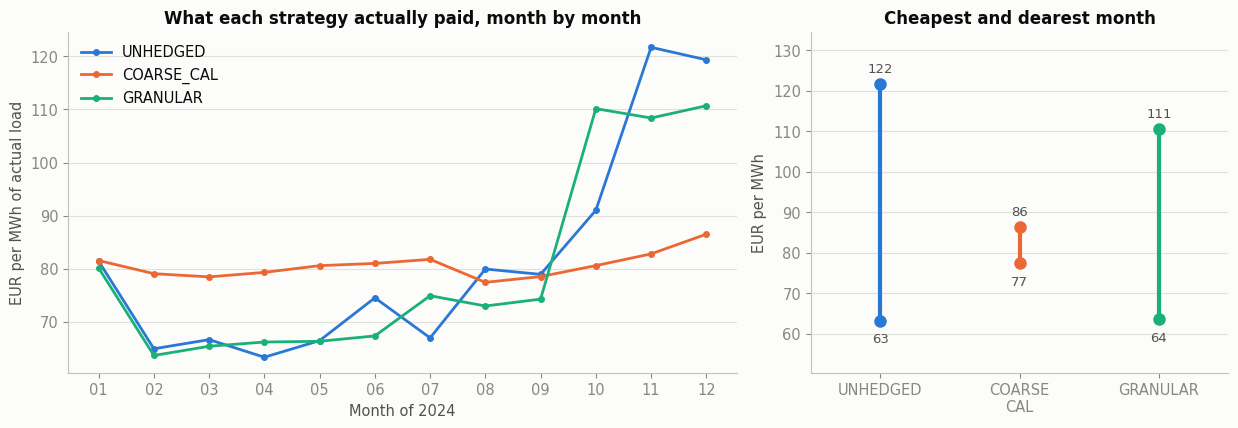

         UNHEDGED  COARSE_CAL  GRANULAR
m                                      
2024-01     81.39       81.51     80.11
2024-02     64.88       79.04     63.62
2024-03     66.60       78.44     65.36
2024-04     63.29       79.29     66.15
2024-05     66.42       80.55     66.29
2024-06     74.49       80.97     67.30
2024-07     66.94       81.74     74.88
2024-08     79.92       77.41     72.95
2024-09     78.91       78.49     74.24
2024-10     90.99       80.56    110.16
2024-11    121.72       82.77    108.39
2024-12    119.36       86.48    110.70


In [39]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4),
                               gridspec_kw={'width_ratios': [1.6, 1]})

xi = range(len(mprice))
for n in STRATEGIES:
    ax1.plot(xi, mprice[n].values, color=SCOL[n], linewidth=2, marker='o', markersize=4, label=n)
ax1.set_xticks(list(xi)); ax1.set_xticklabels([m[5:] for m in mprice.index])
ax1.set_xlabel('Month of 2024'); ax1.set_ylabel('EUR per MWh of actual load')
ax1.set_title('What each strategy actually paid, month by month')
ax1.legend(loc='upper left'); ax1.grid(axis='x')

# the full-year averages differ by ~1 EUR and would look identical as bars -
# what actually separates the strategies is their spread across months
for k, n in enumerate(STRATEGIES):
    lo, hi = mprice[n].min(), mprice[n].max()
    ax2.vlines(k, lo, hi, color=SCOL[n], linewidth=3)
    ax2.plot([k, k], [lo, hi], 'o', color=SCOL[n], markersize=8)
    ax2.annotate(f'{hi:,.0f}', (k, hi), xytext=(0, 8), textcoords='offset points',
                 ha='center', fontsize=9.5, color=INK_SEC)
    ax2.annotate(f'{lo:,.0f}', (k, lo), xytext=(0, -16), textcoords='offset points',
                 ha='center', fontsize=9.5, color=INK_SEC)
ax2.set_xticks(range(len(STRATEGIES)))
ax2.set_xticklabels([n.replace('_', '\n') for n in STRATEGIES])
ax2.set_xlim(-0.5, len(STRATEGIES) - 0.5)
ax2.set_ylabel('EUR per MWh'); ax2.set_title('Cheapest and dearest month')
ax2.grid(axis='x'); ax2.margins(y=0.22)

FIGURES['s6_monthly_cost'] = fig
plt.tight_layout(); plt.show()

print(mprice.round(2).to_string())

## Stage 6 — the recommendation

### What the numbers say

| Measure | UNHEDGED | COARSE_CAL | GRANULAR |
|---|---|---|---|
| Final cost | €3,537,208 | **€3,481,470** | €3,482,011 |
| Average price | €82.00/MWh | **€80.71** | €80.72 |
| Saving vs unhedged | — | **+€55,737** | +€55,197 |
| Monthly price std | €20.15 | **€2.43** | €18.56 |
| Monthly price range | €58.43 | **€9.08** | €47.08 |
| Absolute residual DA volume | 43,000 MWh | 12,760 | **11,985** |
| Residual RMSE | 1.319 MWh | 0.442 | **0.421** |
| Imbalance cost | €30,504 | €30,504 | €30,504 |

**On cost the two hedges are a tie.** They differ by **€541** on €3.48 million —
**0.016%**. That gap is smaller than any real-world transaction cost and is pure
luck: it reflects where 2024's prices happened to land relative to the forward
curve, not a difference in design quality. **Reporting COARSE_CAL as "the cheaper
strategy" would be reading noise as signal.**

**On shape quality GRANULAR wins**, but modestly: 4.7% better RMSE and 775 MWh
less absolute Day-Ahead traffic.

### The monthly-stability trap

COARSE_CAL's monthly standard deviation is **€2.43** against GRANULAR's **€18.56**
— it looks eight times more stable. **This measure is misleading, and the
recommendation should not follow it.**

CAL charges one annual price to every month, so of course the monthly series is
flat. GRANULAR charges each block its own quoted price, so October–December carry
Q4's €101.39 while spring carries Q2's €66.23. The monthly variation is real, but
it was **fixed and known on 29 September 2023**. It is not uncertainty.

The right question is not "which line is flatter" but "which line could still
move". Both are equally locked; the flat one just hides the seasonality inside an
average. Meanwhile UNHEDGED's €20.15 is genuine risk — its November and December
came in at €121.72 and €119.36 and nobody knew that in advance.

### Recommendation: **GRANULAR**

Not because it was cheaper — it was not, by €541. Because of what it does when
things go wrong.

**1. It is materially better protected in the tail.** On 12 December 2024, the
worst Day-Ahead day of the year, the excess cost above a normal day was:

| | Excess cost |
|---|---|
| UNHEDGED | €47,188 |
| COARSE_CAL | €5,106 |
| **GRANULAR** | **€1,706** |

GRANULAR was **three times better protected than COARSE_CAL** on the day it
mattered most. That is the difference between the two strategies — invisible in
the annual average, decisive in the tail.

**2. It matches risk where risk concentrates.** Q4 is both our highest-volume
quarter and the most expensive block. CAL under-covers exactly there, because one
annual average cannot buy more in winter.

**3. Its cost is more precisely known in advance.** Six value-neutrality
constraints instead of one means the hedge is value-correct *in each block*, not
merely on average across the year.

**Honest caveats.** GRANULAR trades six products instead of one, so in reality it
crosses the bid-ask spread six times and rounds to whole lots six times — costs
this exercise excludes, and which would eat into a €541 gap many times over. It
also depends on M01–M03 staying liquid. If execution costs were modelled,
**COARSE_CAL would be entirely defensible**: it captures roughly 90% of the tail
protection for a fraction of the trading effort.

**What is not in doubt:** both hedges beat UNHEDGED by about €55,000 and cut
worst-day exposure by more than 70%. The choice between them is a refinement.
The choice to hedge at all is not.

---
# Stage 7 — The worst price day of 2024

> **The brief asks:** *"Identify a relevant high-price day or interval in the 2024
> Day-Ahead data... Compare how the three strategies were exposed and explain how
> the event affected procurement cost... If the company had not hedged, how could
> an extreme spot-price event affect its liquidity and ability to continue serving
> customers? Which risks would remain even with the hedge?"*

We rank every day of 2024 by its average Day-Ahead price and take the worst.

In [40]:
t_local = load['timestamp_local']
daily_da = pd.DataFrame({'d': t_local.dt.date, 'p': P_da}).groupby('d')['p'].mean()
print('Highest daily average Day-Ahead prices of 2024:')
print(daily_da.sort_values(ascending=False).head(5).round(2).to_string())
print(f"\nAnnual average for comparison: {P_da.mean():.2f} EUR/MWh")

EVENT = pd.Timestamp('2024-12-12').date()
day   = (t_local.dt.date == EVENT).values
spike = day & (P_da > 300)
print(f"\n--- {EVENT} ---")
print(f"Day average {P_da[day].mean():,.2f} EUR/MWh  |  peak {P_da[day].max():,.2f}  "
      f"|  {P_da[day].mean()/P_da.mean():.1f}x the annual average")
print(f"Intervals above 300 EUR/MWh: {spike.sum()} ({spike.sum()*DT_H:.1f} hours), "
      f"{t_local[spike].min():%H:%M} to {t_local[spike].max():%H:%M}")
print(f"reBAP that day stayed calm : mean {P_imb[day].mean():,.2f} EUR/MWh")

Highest daily average Day-Ahead prices of 2024:
d
2024-12-12   395.34
2024-12-11   266.54
2024-11-06   231.09
2024-12-04   182.47
2024-12-13   178.47

Annual average for comparison: 78.51 EUR/MWh

--- 2024-12-12 ---
Day average 395.34 EUR/MWh  |  peak 936.28  |  5.0x the annual average
Intervals above 300 EUR/MWh: 52 (13.0 hours), 07:00 to 19:45
reBAP that day stayed calm : mean 233.12 EUR/MWh


In [41]:
rows = []
for n in STRATEGIES:
    H = hedge[n]['H']; R = L - H
    cost = monthly_cost(n)
    for label, m in [('spike hours (>300)', spike), ('whole day', day)]:
        rows.append({'strategy': n, 'window': label,
                     'load MWh': L[m].sum(), 'hedge MWh': H[m].sum(),
                     'residual MWh': R[m].sum(), 'cost EUR': cost[m].sum(),
                     'EUR per MWh': cost[m].sum() / A[m].sum()})
event = pd.DataFrame(rows)
event

,strategy,window,load MWh,hedge MWh,residual MWh,cost EUR,EUR per MWh
0,UNHEDGED,spike hours (>300),89.69,0.00,89.69,"55,700.73",588.70
1,UNHEDGED,whole day,132.44,0.00,132.44,"63,310.57",453.78
2,COARSE_CAL,spike hours (>300),89.69,79.71,9.98,"13,798.50",145.84
3,COARSE_CAL,whole day,132.44,128.02,4.42,"18,038.98",129.29
4,GRANULAR,spike hours (>300),89.69,86.15,3.54,"13,109.78",138.56
5,GRANULAR,whole day,132.44,137.37,-4.92,"18,383.49",131.76


A normal 2024 interval cost 77.64 EUR/MWh. During the 13 spike hours of
2024-12-12 the extra paid ON TOP of that normal price was:

   UNHEDGED        47,188 EUR      (if it had lasted 3x longer:    141,565 EUR)
   COARSE_CAL       5,106 EUR      (if it had lasted 3x longer:     15,317 EUR)
   GRANULAR         1,706 EUR      (if it had lasted 3x longer:      5,117 EUR)


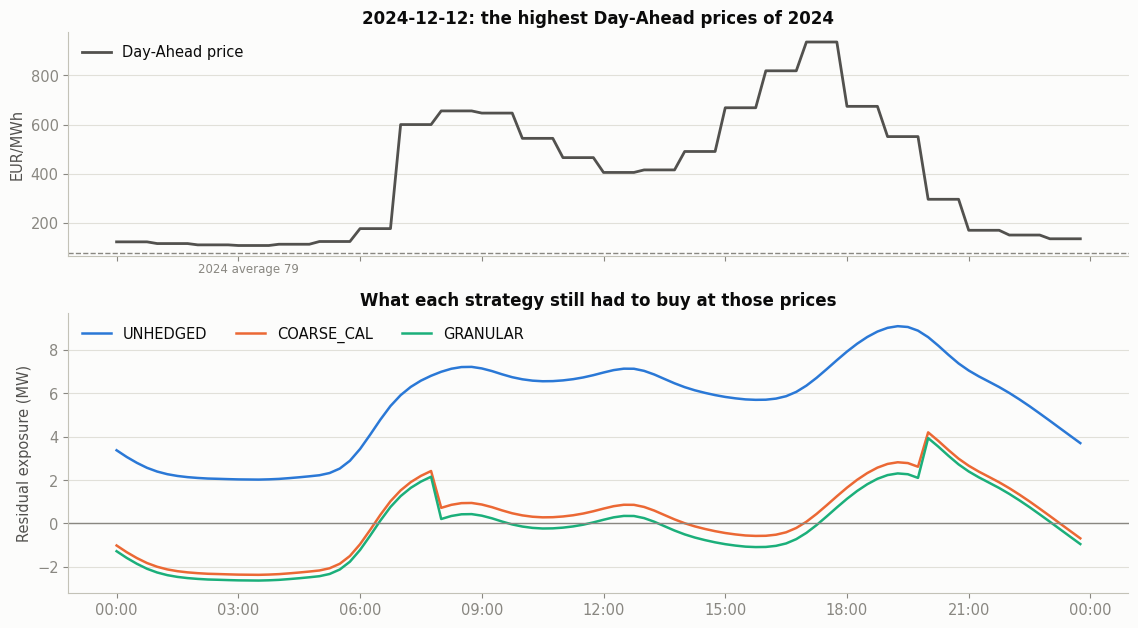

In [42]:
normal = P_da[~day].mean()
print(f"A normal 2024 interval cost {normal:,.2f} EUR/MWh. During the 13 spike hours of")
print(f"{EVENT} the extra paid ON TOP of that normal price was:\n")
for n in STRATEGIES:
    R = L - hedge[n]['H']
    extra = ((P_da[spike] - normal) * R[spike]).sum()
    print(f"   {n:11s} {extra:10,.0f} EUR      (if it had lasted 3x longer: {3*extra:10,.0f} EUR)")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11.5, 6.4), sharex=True,
                               gridspec_kw={'height_ratios': [1, 1.25]})
td = t_local[day]

ax1.plot(td, P_da[day], color=INK_SEC, linewidth=2, label='Day-Ahead price')
ax1.axhline(P_da.mean(), color=INK_MUTE, linewidth=1, linestyle='--')
ax1.annotate(f'2024 average {P_da.mean():.0f}', xy=(td.iloc[8], P_da.mean()),
             xytext=(0, -14), textcoords='offset points', ha='left',
             color=INK_MUTE, fontsize=8.5)
ax1.set_ylabel('EUR/MWh'); ax1.set_title(f'{EVENT}: the highest Day-Ahead prices of 2024')
ax1.legend(loc='upper left'); ax1.grid(axis='x')

for n in STRATEGIES:
    ax2.plot(td, (L - hedge[n]['H'])[day] / DT_H, color=SCOL[n], linewidth=1.8, label=n)
ax2.axhline(0, color=INK_MUTE, linewidth=1)
ax2.set_ylabel('Residual exposure (MW)')
ax2.set_title('What each strategy still had to buy at those prices')
ax2.legend(loc='upper left', ncol=3); ax2.grid(axis='x')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

FIGURES['s7_severe_event'] = fig
plt.tight_layout(); plt.show()

## Stage 7 — answers

### The event

**12 December 2024** — a dark, still winter weekday. The Day-Ahead average was
**€395.34/MWh**, five times the annual average of €78.51, and it peaked at
**€936.28/MWh** at 17:00. Prices stayed above €300/MWh for **13 straight hours**,
07:00 to 19:45 — the entire working day.

Crucially, **reBAP did not blow up**: it averaged **€233/MWh** on the day —
elevated, but only a little over half the Day-Ahead average and nowhere near the
€15,000 spikes reBAP reached in June. This is a pure **price** event, not a
balancing crisis. It is precisely the scenario futures
exist to protect against, which makes it the right test for comparing the three
strategies.

### Q: How was each strategy exposed?

During the 13 spike hours we consumed **89.7 MWh**:

| | Residual still to buy | Cost | Effective price |
|---|---|---|---|
| UNHEDGED | 89.69 MWh (all of it) | €55,701 | **€588.70/MWh** |
| COARSE_CAL | 9.98 MWh | €13,799 | €145.84/MWh |
| GRANULAR | 3.54 MWh | €13,110 | **€138.56/MWh** |

The hedged strategies paid roughly **a quarter** of the unhedged price. Both
saved about **75%** of the day's cost — €41,902 and €42,591 respectively.

The difference between the two hedges is visible in the residual: COARSE_CAL
still had to buy **10 MWh** at crisis prices, GRANULAR only **3.5 MWh** — because
GRANULAR's Q4 position (4.656 MW Base + 2.135 MW Peak) is sized for winter, while
CAL's single annual position (4.392 + 1.884 MW) is an average of the whole year
and is structurally too small in December.

Measured as excess over a normal day, GRANULAR paid **€1,706** and COARSE_CAL
**€5,106** — GRANULAR was **three times better protected**. This single day is
where the two strategies actually differ, and it is the main evidence behind the
Stage 6 recommendation.

### Q: What would an extreme spot event do to an unhedged supplier's liquidity?

**One day would not bankrupt us — but that is the wrong conclusion to draw.**

Unhedged, 12 December cost **€63,311** for a single day's electricity, against a
typical day of about €9,700. The excess was roughly **€47,000 on one day**, or
about **1.3%** of the entire annual procurement budget consumed in 24 hours.

The danger is not the size but the **timing mismatch**. Wholesale power is settled
within days. Our customers pay a fixed monthly bill, weeks later. So an unhedged
supplier must fund the entire spike **out of working capital** before any of it
can be recovered — and it can never be recovered from a fixed-price customer at
all. A hedged supplier faces no such gap: the futures payoff arrives at the same
time as the high spot cost, cancelling it.

Now scale it. December 2024 had **three** days averaging above €175/MWh. A
sustained cold, windless spell — the German *Dunkelflaute* — can run one to two
weeks. If the 12 December conditions had persisted for three such days, the
unhedged excess would be roughly **€142,000**; COARSE_CAL **€15,300**; GRANULAR
**€5,100**. Two weeks would be a genuine solvency question for a small supplier
with thin margins.

This is not hypothetical. Several UK and European retail suppliers failed in
2021–22 for exactly this reason: fixed-price customer books, unhedged wholesale
exposure, and a price shock that outlasted their cash.

### Q: Which risks remain even with the hedge?

**1. Volume risk — completely untouched.** Proven arithmetically in Stage 5: all
three strategies paid the identical **€30,504** imbalance cost. If a cold snap had
made our customers consume 10% more than forecast on 12 December, the extra volume
would have settled at reBAP and no futures position would have helped.

**2. Residual price risk.** GRANULAR still bought 3.54 MWh at crisis prices. The
hedge is a step function; the load is a curve. The gap never closes.

**3. Basis and timing risk on the weekend and late evening.** The structural gaps
from Stage 1 — load after 20:00 and at weekends — are unhedgeable with Base and
Peak products.

**4. The event could have been the *other* kind.** 3 June 2024 saw reBAP reach
**€14,999.99/MWh** while Day-Ahead stayed near €128. On that day the hedge and the
Day-Ahead schedule were both irrelevant, because the loss came from forecast
error meeting a system-stress window. Against that, only forecast accuracy and a
cash buffer help.

**The summary for management:** the hedge converts a large, unpredictable price
exposure into a small, known one. It does not convert an uncertain business into a
certain one.

---
# Assumptions and limitations

> **The brief asks:** *"Select at least three [assumptions] and explain how they
> could affect the hedge, the procurement result, or the management
> recommendation. Where possible, describe the likely direction of the effect."*

### 1. Trading is free and infinitely divisible

No bid-ask spread, no fees, no minimum contract size — the brief excludes them
explicitly. Our positions come out as 4.392 MW and 5.044 MW; real futures trade in
whole-MW lots.

**Direction: this flatters GRANULAR, and it is decisive here.** GRANULAR trades
six products instead of one, so it crosses the spread six times and rounds six
times. The entire cost gap between the two strategies is **€541**; a single
€0.05/MWh spread on 44,000 MWh is €2,200 — four times the gap. **Modelling
execution costs would probably make COARSE_CAL the cheaper strategy.** Our
recommendation of GRANULAR therefore rests on tail protection, not on cost — which
is exactly how it is argued in Stage 6.

### 2. The customer book is frozen

We assume the same 10,220 customers all year. Real German retail churn runs at a
few percent annually, and a fixed-price offer attracts switching in both
directions.

**Direction: losing customers leaves us over-hedged.** Futures cannot be undone
without selling them back at the prevailing price. Churn silently converts a hedge
into a speculative long position — and since customers are most likely to leave
when prices fall, we would be selling back into a weak market. The risk is
asymmetric and lands during delivery, when nothing can be done about it.

### 3. The forecast contains no weather

A standard load profile does not know that February 2024 was mild. Our 2% forecast
error looks reassuring, but its *structure* matters more than its size.

**Direction: errors cluster on the worst days.** A cold snap makes every supplier
under-forecast simultaneously — which is exactly when the system is short and
reBAP is punishing. Our errors are not independent noise; they are correlated with
the price of being wrong. The €30,504 imbalance cost is a good year's number, not
a typical one.

### 4. The historical shape carries the 2021–22 gas crisis

September and November are the reddest months in the shape data (evening factors
of 2.33 and 2.35) while January and February reach only 1.15. That ordering is not
seasonal — it is one extraordinary autumn inside a four-year average.

**Direction: the HPFC overstates September and November and understates
deep-winter evenings.** We expected this to distort the positions, since value
neutrality is enforced on the HPFC and November sits inside Q4 — our
highest-volume, most expensive block. **We tested it and we were wrong.** Rebuilding
the shape with September and November replaced by their neighbouring months moves
Q4 Base by **+0.08%** and the annual cost by **€40** (robustness check at the end of
Stage 3). The constraint is a block-level average on a curve whose block means are
pinned by traded prices, so shape distortion is a second-order effect.

The defect is real for **valuation** — do not use this curve to argue what
September costs — but it does not undermine the hedge recommendation.

### 5. No public holidays

1 January 2024 is treated as a normal Monday with Peak hours from 08:00. Real
holidays price like Sundays.

**Direction: small and systematic.** The curve overstates prices on roughly ten
days a year, biasing the Peak/Off-Peak split slightly. Too small to change the
recommendation.

### 6. No credit, margin or counterparty risk

A future is a promise from a counterparty, and holding one requires posting margin
when prices move against you.

**Direction: it partly undoes the liquidity argument in Stage 7.** We argued that
hedging protects working capital. But a hedge that moves €55,000 in our favour was
also posting margin along the way, and in the opposite scenario — a price collapse
— the hedge itself would have demanded cash precisely when revenues fell. Hedging
does not remove cash-flow risk; it changes its shape.

---

### What we would do next with more time

- Rebuild the shape factors excluding 2022, and check whether the Q4 positions move.
- Run the same optimisation against several weather scenarios rather than one
  fixed profile, to see how much of the €55,000 saving survives.
- Add a spread and lot-size model, and re-run the COARSE_CAL vs GRANULAR
  comparison — the honest test of the recommendation.

---
# Appendix — Presentation pack

Everything needed for the 10–15 minute presentation, collected in one place so you
do not have to hunt back through the notebook.

### Suggested slide order

1. **The decision** — 10,220 customers, 43,000 MWh, fixed prices, wholesale risk.
2. **The book** — Exhibit 1 charts. Peaked, weekend-heavy, winter-weighted.
3. **What we can trade** — Exhibit 2. The liquidity cliff and the three coverage sets.
4. **The curve** — Stage 2 reconciliation evidence. It matches the market.
5. **…but it is not a forecast** — the duration-curve chart.
6. **The hedge** — Stage 3 positions and the winter-week fit chart.
7. **Value neutral, not volume neutral** — the +1,504 / +1,079 MWh result.
8. **What it cost** — Stage 6 table and monthly chart.
9. **The worst day** — Stage 7. €588.70 vs €138.56 per MWh.
10. **Recommendation and caveats** — GRANULAR on tail evidence, not on cost.

---
## The eight required deliverables, in order

> *"The analysis and presentation must include: an HPFC reconciliation table; a
> futures-position table; a final cost-and-risk comparison table; the customer
> portfolio shape and composition; the HPFC shape and contract-reconciliation
> evidence; the forecast load, hedge shape, and residual exposure; a monthly
> procurement cost or price comparison; and the selected severe-price-event
> analysis."*

All eight are reproduced below, numbered in the brief's own order, so they can be
lifted straight into slides. Every chart is also written to a **`presentation/`**
folder as a PNG at 150 dpi.

These are the same objects as in the narrative above, not redrawn copies — the
charts were kept in a `FIGURES` dictionary as they were created, so the two can
never drift apart.


1. HPFC reconciliation table

  calibration blocks


,period,quoted Base,HPFC Base,Base error,quoted Peak,HPFC Peak,Peak error
0,M01,75.32,75.32,0.00,88.68,88.68,0.00
1,M02,60.09,60.09,-0.00,70.59,70.59,0.00
2,M03,63.45,63.45,0.00,72.79,72.79,0.00
3,Q2,66.23,66.23,-0.00,64.76,64.76,0.00
4,Q3,74.74,74.74,-0.00,69.07,69.07,-0.00
5,Q4,101.39,101.39,0.00,134.42,134.42,0.00



  independent checks


,period,quoted Base,HPFC Base,Base error,quoted Peak,HPFC Peak,Peak error,tradable
0,Q1,66.42,66.42,0.00,77.70,77.70,0.00,True
1,CAL,77.26,77.26,-0.00,86.60,86.60,0.00,True
2,M04,67.11,62.11,-5.00,72.56,59.18,-13.38,False
3,M07,59.45,64.76,5.31,49.47,54.73,5.26,False
4,M12,112.07,96.76,-15.31,159.75,129.72,-30.03,False



2. Futures-position table

  MW per product


strategy  COARSE_CAL      GRANULAR     
load type       BASE PEAK     BASE PEAK
product                                
CAL             4.39 1.88      NaN  NaN
M01              NaN  NaN     5.04 2.33
M02              NaN  NaN     4.93 2.22
M03              NaN  NaN     4.65 1.97
Q2               NaN  NaN     4.00 1.68
Q3               NaN  NaN     3.85 1.54
Q4               NaN  NaN     4.66 2.13


3. Final cost-and-risk comparison table

  eight measures


strategy,UNHEDGED,COARSE_CAL,GRANULAR
final cost EUR,"3,537,207.83","3,481,470.48","3,482,011.18"
EUR per MWh,82.00,80.71,80.72
saving vs unhedged EUR,0.00,"55,737.35","55,196.65"
monthly price std,20.15,2.43,18.56
monthly price range,58.43,9.08,47.08
abs residual DA MWh,"43,000.00","12,760.13","11,985.15"
residual RMSE MWh,1.32,0.44,0.42
imbalance cost EUR,"30,503.84","30,503.84","30,503.84"
imbalance premium EUR,"13,589.24","13,589.24","13,589.24"



4. Customer portfolio shape and composition


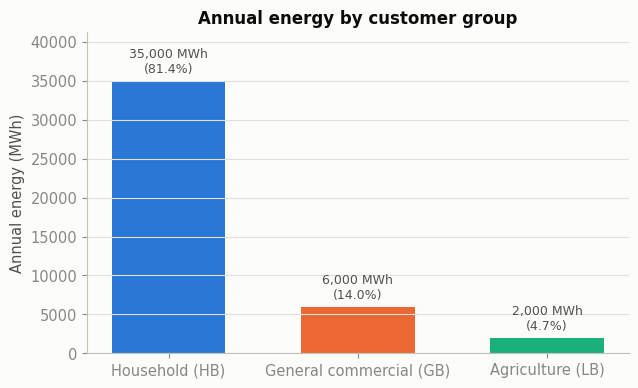

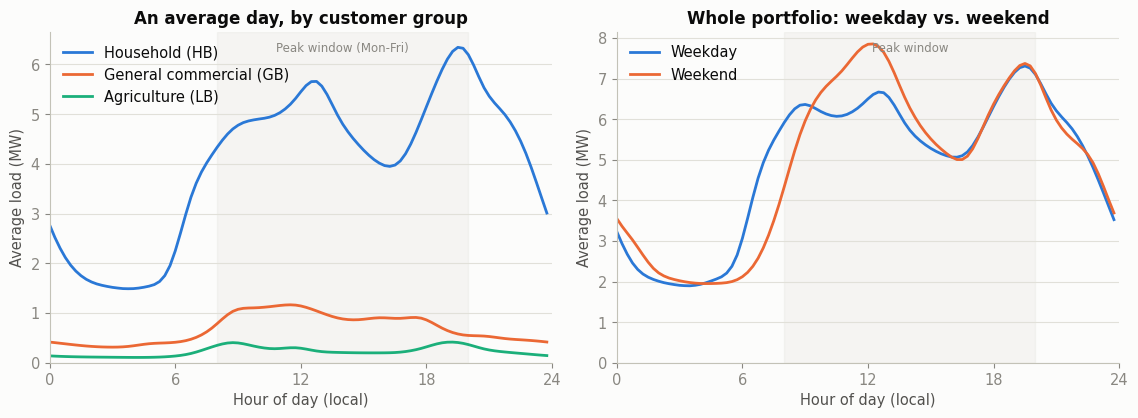


5. HPFC shape and contract-reconciliation evidence


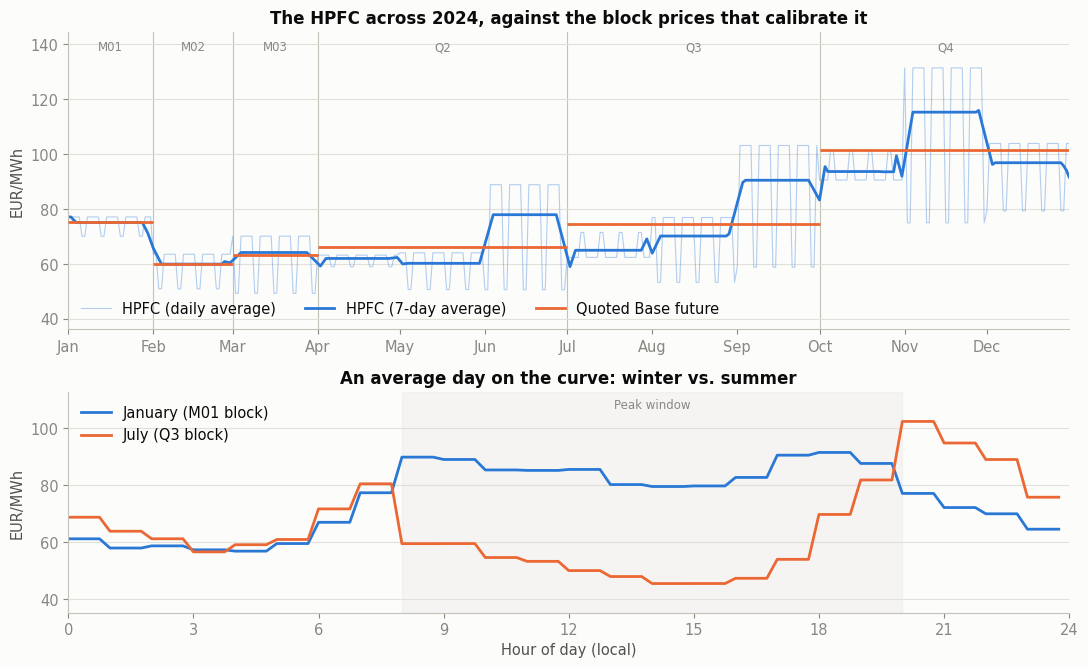

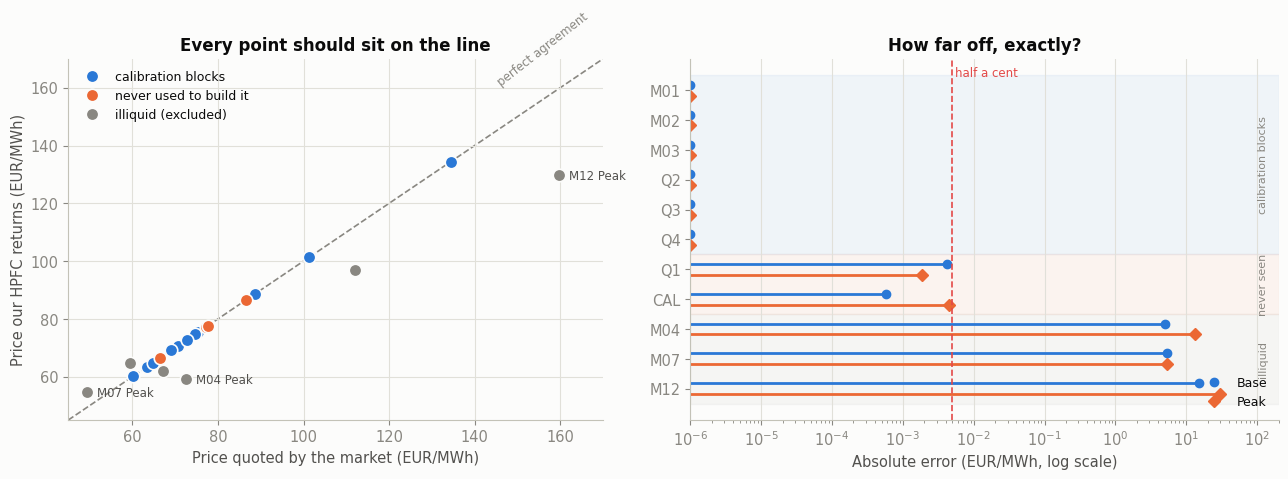

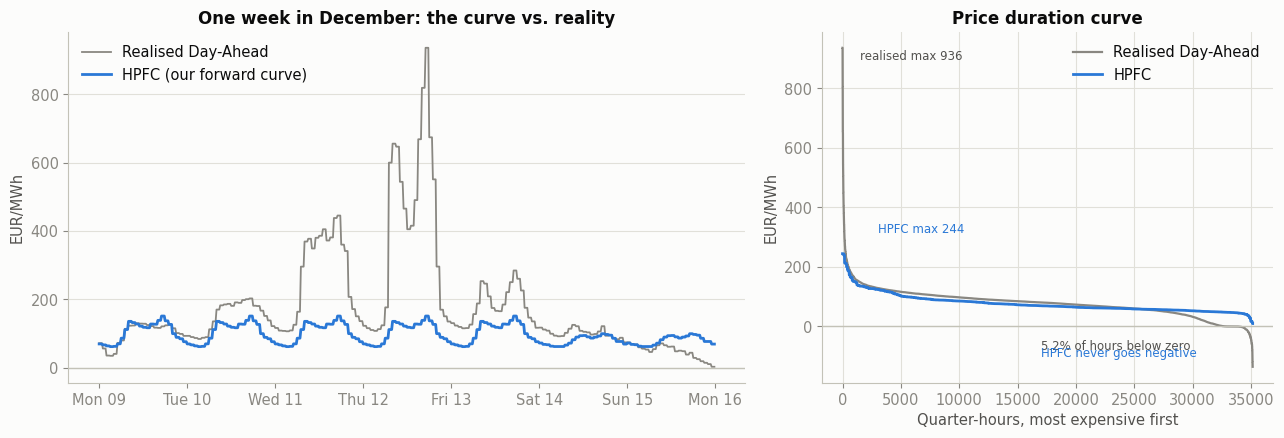


6. Forecast load, hedge shape and residual exposure


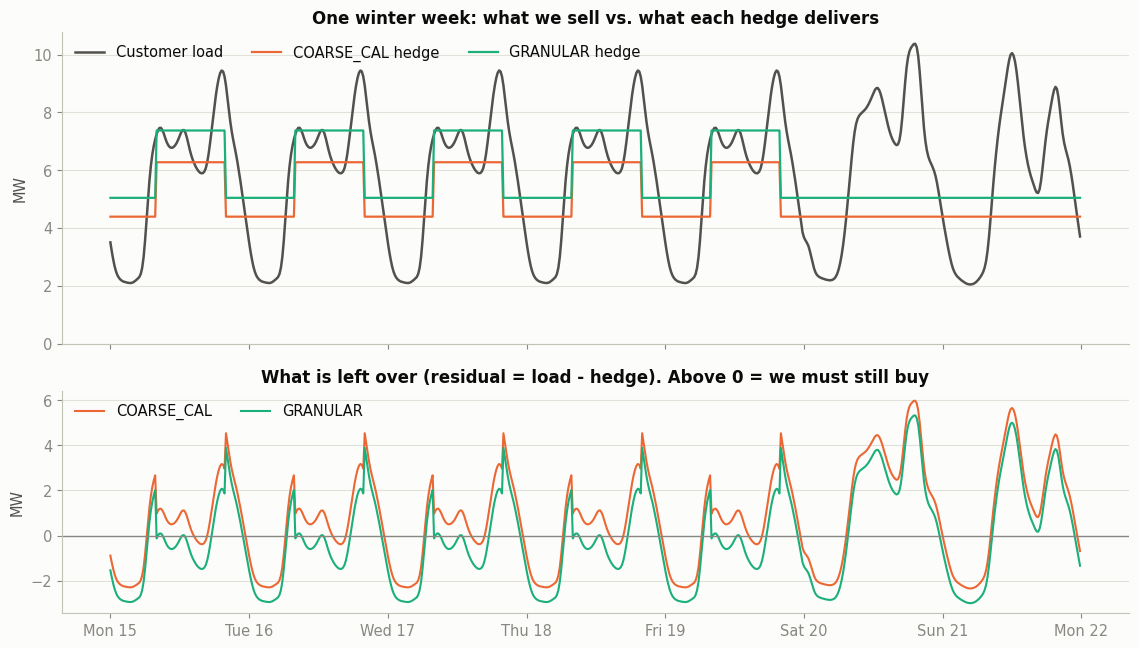


7. Monthly procurement cost comparison

  EUR per MWh of actual load


,UNHEDGED,COARSE_CAL,GRANULAR
m,,,
2024-01,81.39,81.51,80.11
2024-02,64.88,79.04,63.62
2024-03,66.60,78.44,65.36
2024-04,63.29,79.29,66.15
2024-05,66.42,80.55,66.29
2024-06,74.49,80.97,67.30
2024-07,66.94,81.74,74.88
2024-08,79.92,77.41,72.95
2024-09,78.91,78.49,74.24


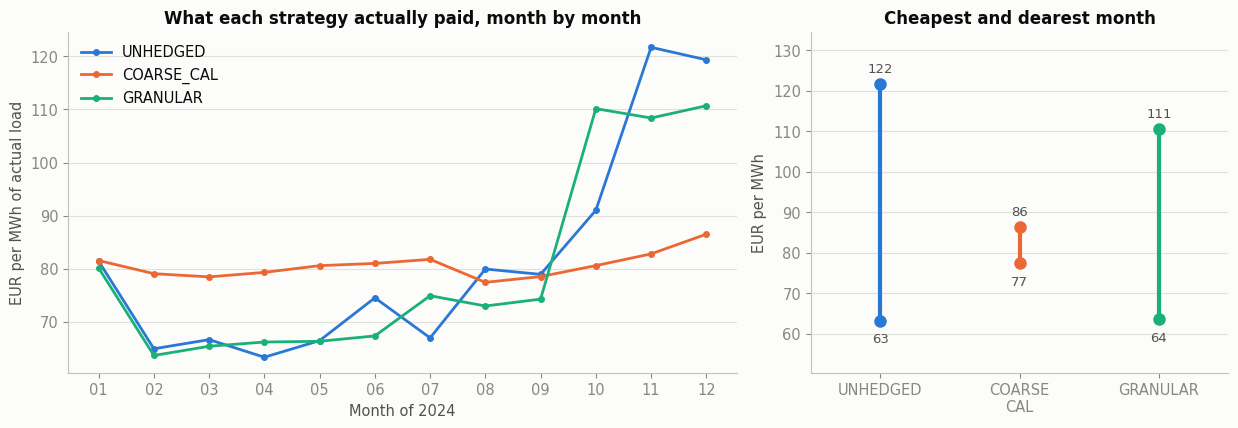


8. Severe-price-event analysis

  2024-12-12


,strategy,window,load MWh,hedge MWh,residual MWh,cost EUR,EUR per MWh
0,UNHEDGED,spike hours (>300),89.69,0.00,89.69,"55,700.73",588.70
1,UNHEDGED,whole day,132.44,0.00,132.44,"63,310.57",453.78
2,COARSE_CAL,spike hours (>300),89.69,79.71,9.98,"13,798.50",145.84
3,COARSE_CAL,whole day,132.44,128.02,4.42,"18,038.98",129.29
4,GRANULAR,spike hours (>300),89.69,86.15,3.54,"13,109.78",138.56
5,GRANULAR,whole day,132.44,137.37,-4.92,"18,383.49",131.76


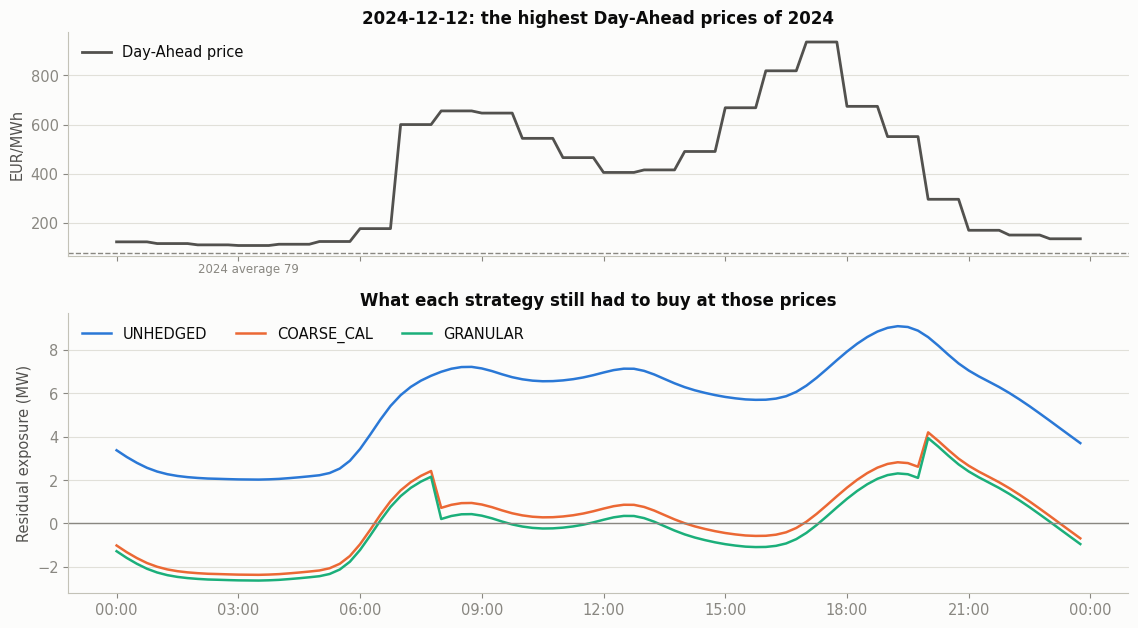


8 charts written to ./presentation/
    presentation/ex1_portfolio_composition.png
    presentation/ex1_portfolio_shape.png
    presentation/s2_hpfc_curve.png
    presentation/s2_hpfc_reconciliation.png
    presentation/s2_hpfc_vs_realised.png
    presentation/s3_hedge_fit.png
    presentation/s6_monthly_cost.png
    presentation/s7_severe_event.png


In [43]:
import os
from IPython.display import display

os.makedirs('presentation', exist_ok=True)

DELIVERABLES = [
    ('1. HPFC reconciliation table',
     ['table:hpfc_recon'], None),
    ('2. Futures-position table',
     ['table:positions'], None),
    ('3. Final cost-and-risk comparison table',
     ['table:comparison'], None),
    ('4. Customer portfolio shape and composition',
     [], ['ex1_portfolio_composition', 'ex1_portfolio_shape', 's1_portfolio_shape']),
    ('5. HPFC shape and contract-reconciliation evidence',
     [], ['s2_hpfc_curve', 's2_hpfc_reconciliation', 's2_hpfc_vs_realised']),
    ('6. Forecast load, hedge shape and residual exposure',
     [], ['s3_hedge_fit']),
    ('7. Monthly procurement cost comparison',
     ['table:monthly'], ['s6_monthly_cost']),
    ('8. Severe-price-event analysis',
     ['table:event'], ['s7_severe_event']),
]

TABLES = {
    'hpfc_recon': [('calibration blocks', calib.drop(columns='tradable')),
                   ('independent checks',  reconcile(['Q1', 'CAL', 'M04', 'M07', 'M12']))],
    'positions':  [('MW per product', positions.pivot_table(
                        index='product', columns=['strategy', 'load type'], values='position MW')
                        .reindex(['CAL', 'M01', 'M02', 'M03', 'Q2', 'Q3', 'Q4']))],
    'comparison': [('eight measures', comparison.set_index('strategy').T)],
    'monthly':    [('EUR per MWh of actual load', mprice.round(2))],
    'event':      [(f'{EVENT}', event)],
}

saved = []
for title, tabs, figs in DELIVERABLES:
    print('\n' + '=' * 74); print(title); print('=' * 74)
    for t in tabs:
        for label, tbl in TABLES[t.split(':')[1]]:
            print(f'\n  {label}')
            display(tbl)
    for key in (figs or []):
        fig = FIGURES.get(key)
        if fig is None:
            continue                       # that chart lives in the other notebook variant
        path = f'presentation/{key}.png'
        fig.savefig(path, dpi=150, bbox_inches='tight', facecolor=SURFACE)
        saved.append(path)
        display(fig)

print('\n' + '=' * 74)
print(f'{len(saved)} charts written to ./presentation/')
for pth in saved:
    print('   ', pth)

In [44]:
line = '=' * 76
print(line); print('HEADLINE NUMBERS'); print(line)

print('\nTHE BOOK')
print(f'  customers                     10,220 across three profiles')
print(f'  annual energy                 {L.sum():,.0f} MWh')
print(f'  average / peak / trough load  {L.sum()/(len(L)*DT_H):.2f} / {L.max()/DT_H:.2f} / {L.min()/DT_H:.2f} MW')
print(f'  load factor                   {L.mean()/L.max():.0%}')
print(f'  energy inside the Peak window {L[pk_mask].sum()/L.sum():.1%}  (Peak is {pk_mask.mean():.1%} of the year)')

print('\nTHE CURVE (Stage 2)')
print(f'  worst error on the 6 blocks it was built from  {calib[["Base error","Peak error"]].abs().max().max():.1e} EUR/MWh')
_ind = reconcile(['Q1', 'CAL'])
print(f'  worst error on Q1 and CAL, never used          {_ind[["Base error","Peak error"]].abs().max().max():.4f} EUR/MWh')
print(f'  HPFC range  {hpfc.min():,.0f} to {hpfc.max():,.0f} EUR/MWh, never negative')
print(f'  realised DA {P_da.min():,.0f} to {P_da.max():,.0f} EUR/MWh, {(P_da<0).mean():.1%} negative')

print('\nTHE HEDGE (Stage 3)')
for n in ['COARSE_CAL', 'GRANULAR']:
    H = hedge[n]['H']
    print(f'  {n:11s} {len(hedge[n]["prods"]):2d} products | {H.sum():,.0f} MWh bought vs {L.sum():,.0f} sold '
          f'({H.sum()-L.sum():+,.0f}) | RMSE {np.sqrt(((L-H)**2).mean()):.4f}')

print('\nTHE OUTCOME (Stage 6)')
for _, r in comparison.iterrows():
    print(f'  {r["strategy"]:11s} {r["final cost EUR"]:>12,.0f} EUR | {r["EUR per MWh"]:6.2f} EUR/MWh | '
          f'saving {r["saving vs unhedged EUR"]:>9,.0f} EUR')
print(f'  imbalance cost, identical for all three        {C_imb:,.0f} EUR')
print(f'  gap between the two hedges                     {abs(comparison["final cost EUR"].iloc[1]-comparison["final cost EUR"].iloc[2]):,.0f} EUR'
      f'  ({abs(comparison["final cost EUR"].iloc[1]-comparison["final cost EUR"].iloc[2])/comparison["final cost EUR"].iloc[1]:.3%})')

print(f'\nTHE WORST DAY ({EVENT})')
print(f'  Day-Ahead average {P_da[day].mean():,.0f} EUR/MWh, peak {P_da[day].max():,.0f}, '
      f'{spike.sum()*DT_H:.0f} hours above 300')
for n in STRATEGIES:
    R = L - hedge[n]['H']
    sub = event[(event.strategy == n) & (event.window == 'spike hours (>300)')].iloc[0]
    print(f'  {n:11s} residual {sub["residual MWh"]:6.2f} MWh | paid {sub["EUR per MWh"]:7.2f} EUR/MWh | '
          f'excess over a normal day {((P_da[spike]-normal)*R[spike]).sum():8,.0f} EUR')
print(line)

HEADLINE NUMBERS

THE BOOK
  customers                     10,220 across three profiles
  annual energy                 43,000 MWh
  average / peak / trough load  4.90 / 10.40 / 1.68 MW
  load factor                   47%
  energy inside the Peak window 44.5%  (Peak is 35.8% of the year)

THE CURVE (Stage 2)
  worst error on the 6 blocks it was built from  2.8e-14 EUR/MWh
  worst error on Q1 and CAL, never used          0.0044 EUR/MWh
  HPFC range  10 to 244 EUR/MWh, never negative
  realised DA -135 to 936 EUR/MWh, 5.2% negative

THE HEDGE (Stage 3)
  COARSE_CAL   2 products | 44,504 MWh bought vs 43,000 sold (+1,504) | RMSE 0.4417
  GRANULAR    12 products | 44,079 MWh bought vs 43,000 sold (+1,079) | RMSE 0.4213

THE OUTCOME (Stage 6)
  UNHEDGED       3,537,208 EUR |  82.00 EUR/MWh | saving         0 EUR
  COARSE_CAL     3,481,470 EUR |  80.71 EUR/MWh | saving    55,737 EUR
  GRANULAR       3,482,011 EUR |  80.72 EUR/MWh | saving    55,197 EUR
  imbalance cost, identical for all thr

In [45]:
from IPython.display import display

for title, table in [
        ('1. HPFC reconciliation - blocks used to build the curve', calib.drop(columns='tradable')),
        ('2. HPFC reconciliation - independent checks', reconcile(['Q1', 'CAL', 'M04', 'M07', 'M12'])),
        ('3. Futures positions (MW)', positions.pivot_table(
             index='product', columns=['strategy', 'load type'], values='position MW')
             .reindex(['CAL', 'M01', 'M02', 'M03', 'Q2', 'Q3', 'Q4'])),
        ('4. Hedge check (Stage 3)', stage3.set_index('strategy').T),
        ('5. Final cost and risk comparison', comparison.set_index('strategy').T),
        ('6. Monthly procurement price (EUR per MWh of actual load)', mprice.round(2)),
        ('7. Severe price event - 12 December 2024', event)]:
    print(f'\n{title}')
    display(table)


1. HPFC reconciliation - blocks used to build the curve


,period,quoted Base,HPFC Base,Base error,quoted Peak,HPFC Peak,Peak error
0,M01,75.32,75.32,0.00,88.68,88.68,0.00
1,M02,60.09,60.09,-0.00,70.59,70.59,0.00
2,M03,63.45,63.45,0.00,72.79,72.79,0.00
3,Q2,66.23,66.23,-0.00,64.76,64.76,0.00
4,Q3,74.74,74.74,-0.00,69.07,69.07,-0.00
5,Q4,101.39,101.39,0.00,134.42,134.42,0.00



2. HPFC reconciliation - independent checks


,period,quoted Base,HPFC Base,Base error,quoted Peak,HPFC Peak,Peak error,tradable
0,Q1,66.42,66.42,0.00,77.70,77.70,0.00,True
1,CAL,77.26,77.26,-0.00,86.60,86.60,0.00,True
2,M04,67.11,62.11,-5.00,72.56,59.18,-13.38,False
3,M07,59.45,64.76,5.31,49.47,54.73,5.26,False
4,M12,112.07,96.76,-15.31,159.75,129.72,-30.03,False



3. Futures positions (MW)


...

strategy,UNHEDGED,COARSE_CAL,GRANULAR
final cost EUR,"3,537,207.83","3,481,470.48","3,482,011.18"
EUR per MWh,82.00,80.71,80.72
saving vs unhedged EUR,0.00,"55,737.35","55,196.65"
monthly price std,20.15,2.43,18.56
monthly price range,58.43,9.08,47.08
abs residual DA MWh,"43,000.00","12,760.13","11,985.15"
residual RMSE MWh,1.32,0.44,0.42
imbalance cost EUR,"30,503.84","30,503.84","30,503.84"
imbalance premium EUR,"13,589.24","13,589.24","13,589.24"



6. Monthly procurement price (EUR per MWh of actual load)


,UNHEDGED,COARSE_CAL,GRANULAR
m,,,
2024-01,81.39,81.51,80.11
2024-02,64.88,79.04,63.62
2024-03,66.60,78.44,65.36
2024-04,63.29,79.29,66.15
2024-05,66.42,80.55,66.29
2024-06,74.49,80.97,67.30
2024-07,66.94,81.74,74.88
2024-08,79.92,77.41,72.95
2024-09,78.91,78.49,74.24



7. Severe price event - 12 December 2024


,strategy,window,load MWh,hedge MWh,residual MWh,cost EUR,EUR per MWh
0,UNHEDGED,spike hours (>300),89.69,0.00,89.69,"55,700.73",588.70
1,UNHEDGED,whole day,132.44,0.00,132.44,"63,310.57",453.78
2,COARSE_CAL,spike hours (>300),89.69,79.71,9.98,"13,798.50",145.84
3,COARSE_CAL,whole day,132.44,128.02,4.42,"18,038.98",129.29
4,GRANULAR,spike hours (>300),89.69,86.15,3.54,"13,109.78",138.56
5,GRANULAR,whole day,132.44,137.37,-4.92,"18,383.49",131.76
